<a href="https://colab.research.google.com/github/Perez-Alvaro/uber-lyft-dataset/blob/main/Contenido%20Entrega%203/2_Presentacion_Colab/Presentacion_Entrega3_Grupo11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# ¿Cuánto cuesta un viaje y cuándo hay recargo?
## Entrega 3 · Modelado y análisis de resultados

**Uber y Lyft en Boston** · Grupo 11 · Ciencia de Datos 5K1 · UTN FRC · 30/10/2026

Álvaro Pérez · Juan Ignacio Cremona · Ignacio Gil · Federico Gon · Sofía Medina · Facundo Dagnino Dailly

---

**Recorrido:** 1 El problema · 2 Decisiones y por qué · 3 Qué mejoramos y cómo · 4 Modelos y pruebas · 5 Precio · 6 Recargo y accuracy · 7 Balanceo · 8 Modelo final · 9 Matriz de beneficio · 10 Curva ROC y AUC · 11 Qué aprendió el modelo · 12 Validación · 13 Familias de tarifa · 14 Conclusiones

> *Entorno de ejecución → Ejecutar todo* (menos de un minuto). El código está oculto: se ve solo el resultado de cada celda.

In [1]:
# @title Preparación (carga los resultados) { display-mode: "form" }
import json, re, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

CARPETA = "Contenido Entrega 3"

def buscar_raiz():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "6_Resultados" / "metricas.json").exists():
            return base
        if (base / CARPETA / "6_Resultados" / "metricas.json").exists():
            return base / CARPETA
    return None

RAIZ = buscar_raiz()
if RAIZ is None:  # en Colab: se descarga el repositorio una sola vez
    subprocess.run(["git", "clone", "-q", "--depth", "1",
                    "https://github.com/Perez-Alvaro/uber-lyft-dataset.git"], check=True)
    RAIZ = Path("uber-lyft-dataset") / CARPETA

GRAF, RES, DATOS = RAIZ / "5_Graficos", RAIZ / "6_Resultados", RAIZ / "4_Datasets"
M = json.loads(re.sub(r"\bNaN\b", "null", (RES / "metricas.json").read_text(encoding="utf-8")))

def figura(nombre, ancho=1000):
    display(Image(filename=str(GRAF / nombre), width=ancho))

def tabla(df):
    display(df.style.hide(axis="index").set_properties(**{"text-align": "left", "font-size": "13px"})
              .set_table_styles([{"selector": "th", "props": [("text-align", "left"), ("background", "#F2F2F2"), ("font-size", "13px")]}]))

md = lambda s: display(Markdown(s))
num = lambda x, d=3: f"{(0.0 if abs(x) < 0.5 * 10 ** -d else x):.{d}f}".replace(".", ",")
pct = lambda x, d=1: f"{100 * x:.{d}f}".replace(".", ",") + "%"
usd = lambda x: "USD " + num(x, 2)
miles = lambda n: f"{int(n):,}".replace(",", ".")
ic = lambda d, f=pct: f"{f(d['valor'])} (IC 95%: {f(d['bajo'])} a {f(d['alto'])})"
# "C=1e-05" -> "C=0.00001" y "max_depth=None" -> "max_depth=sin límite"
params_txt = lambda t: re.sub(r"\d(?:\.\d+)?e-\d+", lambda m: f"{float(m.group(0)):.10f}".rstrip("0"),
                              t).replace("max_depth=None", "max_depth=sin límite")

# Atajos a los resultados más usados
E = M["A_elegido"]
FIN = M["A_finales"][E]["umbral_opt"]           # modelo elegido con el umbral de la matriz de beneficio
FIN_F1 = M["A_finales"][E]["umbral_f1"]         # el mismo modelo con el umbral de máximo F1
BASE = {b["modelo"]: b for b in M["A_lineas_base"]}
MB = M["A_matriz_beneficio"]
IC = M["A_ic95"]["metricas"]
BM = next(r for r in M["B_regresion"] if (r["modelo"], r["variante"]) == (M["B_mejor"]["modelo"], M["B_mejor"]["variante"]))
BS = next(r for r in M["B_regresion"] if r["modelo"] == M["B_mejor"]["modelo"] and r["variante"] != M["B_mejor"]["variante"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
print("Listo: resultados cargados")

Listo: resultados cargados


## 1 · El problema

**Pregunta del proyecto:** ¿qué determina el precio de un viaje y qué tan bien lo podemos predecir?

| | Objetivo 1 | Objetivo 2 |
|---|---|---|
| **Pregunta** | ¿Cuánto cuesta el viaje? | ¿Esta cotización tiene recargo? |
| **Variable** | `price` (USD) | `has_surge` (sí / no) |
| **Tipo** | Regresión | Clasificación |
| **Datos** | Uber + Lyft · 636.568 cotizaciones | Lyft sin Shared · 255.953 cotizaciones (8,2% con recargo) |
| **Variables predictoras** | Producto, distancia, zonas, hora, día y clima (con y sin `surge_multiplier`) | Las mismas + la tasa histórica de recargo de la ruta · **sin** `price` ni `surge_multiplier` (fuga de datos) |

Partimos del **dataset codificado** de la Entrega 2.

## 2 · Las decisiones que tomamos y por qué

| Decisión | Por qué |
|---|---|
| **Separar por fecha:** entrenamos del 25/11 al 14/12 y probamos con 4 días nuevos (15 al 18/12) | Cotizaciones del mismo minuto y ruta comparten el recargo. Si se mezclan, el modelo reconoce "gemelas" y parece mejor de lo que es. |
| **Validación cruzada temporal en orden** (4 folds) para elegir todo | Cada fold entrena con fechas anteriores y valida con las siguientes. La prueba final no se usa para elegir nada. |
| **Comparamos con una validación cruzada mezclada** (5 folds estratificados) | Para medir cuánto infla los resultados mezclar las fechas (sección 12). |
| **El balanceo se aplica solo al entrenamiento** de cada fold | La validación y la prueba mantienen la proporción real (8% con recargo): queremos saber cómo funciona en el mundo real. |
| **Grillas de hiperparámetros extendidas** hasta que el valor elegido quedara adentro | Si el mejor valor está en el borde, el óptimo podría estar más allá y el parámetro no queda justificado. |
| **El umbral de decisión se elige con una matriz de beneficio** | Pone en dólares lo que vale cada acierto y cada error (sección 9). |
| **Intervalos de confianza del 95%** por bootstrap de horas | Para saber qué tan seguros son los números (las cotizaciones de una misma hora no son independientes). |
| **Modelamos log(price)** | El precio tiene una cola de viajes caros; en log los errores son relativos. |

## 3 · Qué mejoramos respecto de la versión preliminar y cómo

| Antes | Ahora | Cómo lo logramos |
|---|---|---|
| Partición al azar (métricas infladas) | Partición por fecha + validación cruzada temporal | Bloques de fechas consecutivos; se valida siempre con días posteriores |
| Hiperparámetros fijos, sin justificar | Búsqueda en grilla para cada modelo y técnica | `GridSearchCV` con la validación temporal; grillas extendidas hasta que el óptimo quedara adentro |
| Umbral fijo de 0,5 | Umbral elegido con la matriz de beneficio | Se maximiza el beneficio en validación y se aplica tal cual a la prueba |
| Accuracy sin referencia | Accuracy siempre contra líneas base | "Siempre sin recargo", "siempre con recargo", azar y la tasa de la zona de origen |
| Sin interpretación | Importancia de variables, odds ratio, árbol y deciles | Odds ratio con regularización débil para no encogerlos |
| Números sin margen de error | Intervalos de confianza del 95% | Bootstrap de bloques por hora |
| Clasificación multiclase circular | K-Means de los 12 productos | Codo y silueta (k = 3) |
| Se suponía que balancear era necesario | Lo comprobamos | Comparamos sin balanceo con el umbral ajustado (sección 7) |

## 4 · Qué modelos usamos y por qué

Elegimos modelos de **menor a mayor complejidad**, para ver si la complejidad extra vale la pena:

| Modelo | Para qué | Por qué lo elegimos |
|---|---|---|
| **Regresión lineal (Ridge) / logística** | Precio / recargo | Simples e interpretables: son la referencia. La logística es el modelo base de clasificación de la cátedra. |
| **Árbol de decisión** | Ambos | Da reglas fáciles de explicar ("si sale de tal zona y la distancia es menor a…") y capta escalones. |
| **Random forest** | Ambos | Muchos árboles promediados: más estable que un árbol solo. |
| **Gradient boosting** | Recargo | Árboles en serie, cada uno corrige al anterior (la idea de AdaBoost). |
| **K-Means** | Productos | Agrupa los productos según su tarifa, sin variable objetivo (no supervisado). |

Cada modelo se probó con **varias configuraciones**. Mostramos la **más simple**, la **elegida** (mejor en validación) y la **más compleja**.

In [2]:
# @title Pruebas por modelo de recargo (PR-AUC en validación: más alto es mejor) { display-mode: "form" }
filas = []
for modelo, pruebas in M["A_pruebas"].items():
    por_rol = {p["rol"].split(" (")[0]: p for p in pruebas}
    fila = {"Modelo": modelo}
    for rol in ["Más simple", "Elegida", "Más compleja"]:
        p = por_rol.get(rol)
        fila[rol] = f'{num(p["validacion"])} (entren. {num(p["entrenamiento"])})' if p else "= elegida"
    fila["Configuración elegida"] = params_txt(por_rol["Elegida"]["params"])
    filas.append(fila)
tabla(pd.DataFrame(filas))
md("La configuración más compleja rinde mucho mejor en **entrenamiento** que en **validación**: memoriza días puntuales. "
   "Por eso se elige por validación, nunca por entrenamiento.")

Modelo,Más simple,Elegida,Más compleja,Configuración elegida
Regresión logística,"0,119 (entren. 0,130)","0,120 (entren. 0,131)","0,112 (entren. 0,132)",C=0.00003
Árbol de decisión,"0,115 (entren. 0,123)","0,125 (entren. 0,159)","0,103 (entren. 0,427)",criterion=gini · max_depth=12 · min_samples_leaf=500
Random forest,"0,124 (entren. 0,187)","0,126 (entren. 0,510)","0,124 (entren. 0,627)",max_depth=24 · min_samples_leaf=10
Gradient boosting,"0,130 (entren. 0,159)","0,136 (entren. 0,240)","0,132 (entren. 0,424)",learning_rate=0.05 · max_leaf_nodes=15


La configuración más compleja rinde mucho mejor en **entrenamiento** que en **validación**: memoriza días puntuales. Por eso se elige por validación, nunca por entrenamiento.

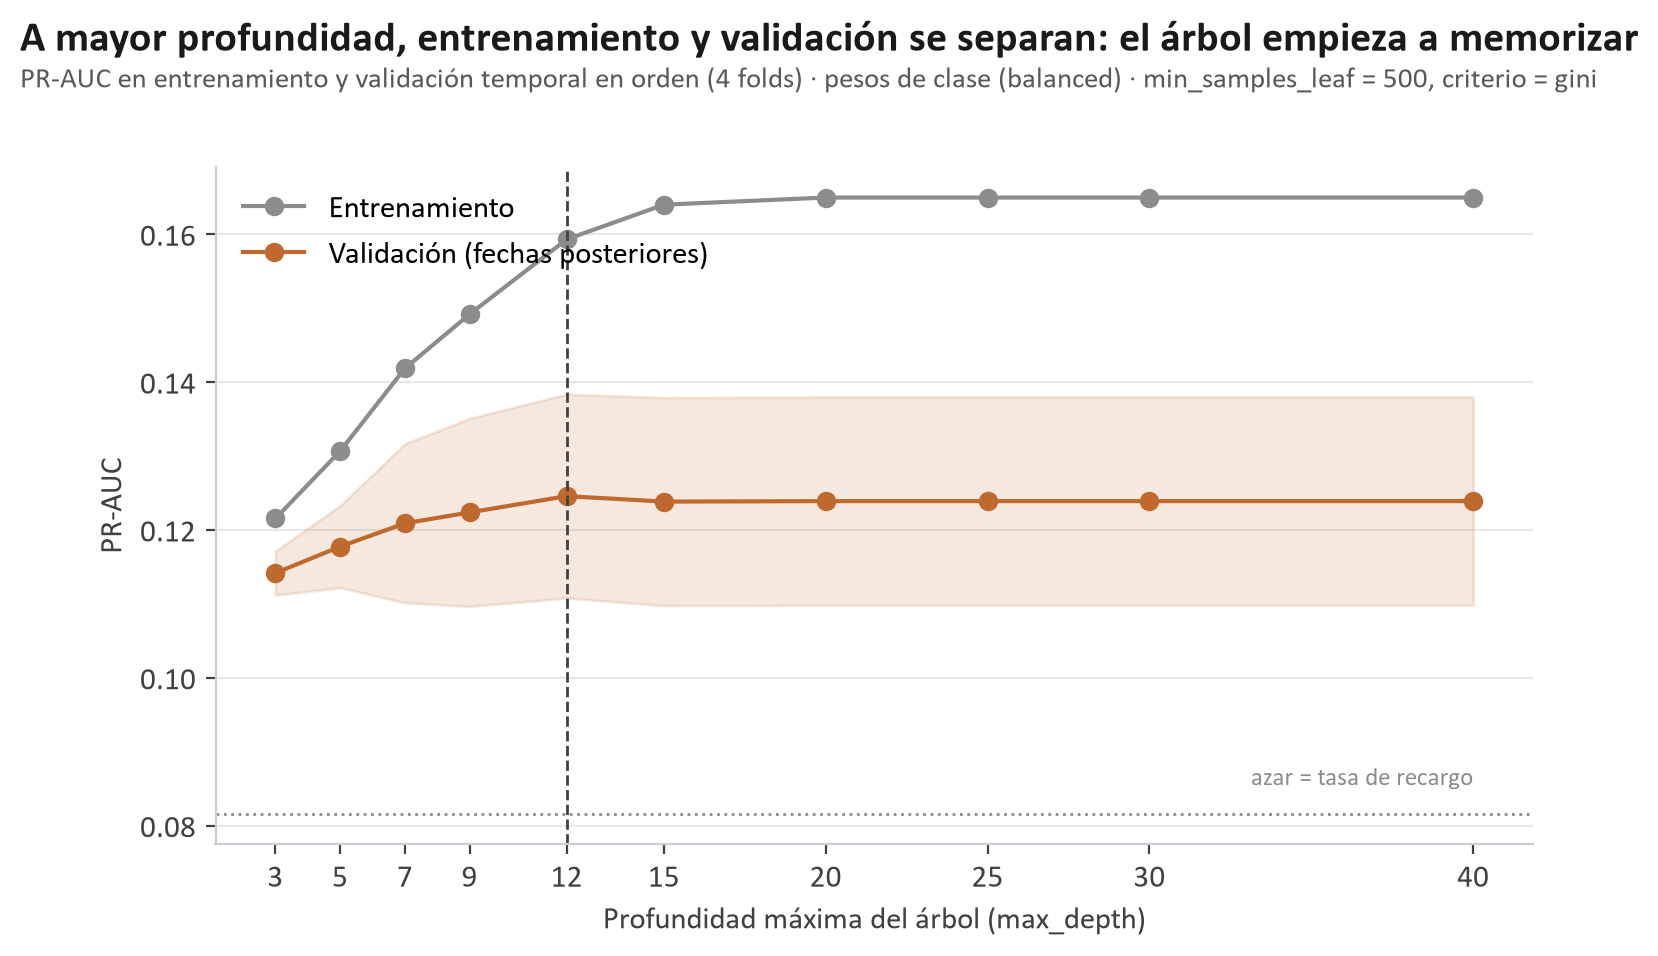

In [3]:
# @title Figura 3 · Ejemplo: probar distintas profundidades del árbol { display-mode: "form" }
figura("fig03_recargo_validacion_profundidad.png", 800)

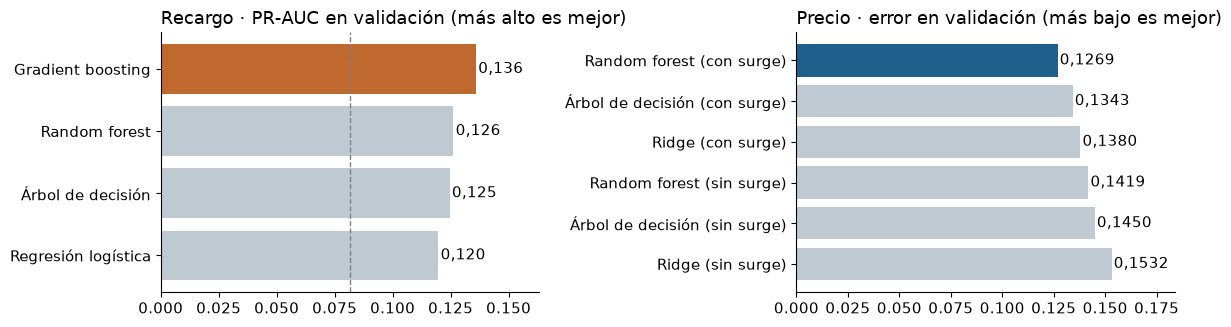

- **Recargo:** gana **gradient boosting**, aunque los cuatro quedan cerca → el límite no es el algoritmo sino la información disponible.
- **Precio:** gana **random forest (con surge)**. Los árboles superan al modelo lineal porque la tarifa crece por escalones.

In [4]:
# @title Y entre modelos: ¿cuál rindió mejor en validación? { display-mode: "form" }
sel = sorted(M["A_seleccion"], key=lambda s: s["pr_auc_val"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
colores = ["#C0692E" if s["modelo"] == E else "#BFC9D1" for s in sel]
axes[0].barh([s["modelo"] for s in sel], [s["pr_auc_val"] for s in sel], color=colores)
for i, s in enumerate(sel):
    axes[0].text(s["pr_auc_val"] + 0.001, i, num(s["pr_auc_val"]), va="center")
axes[0].axvline(M["A_datos"]["tasa_train"], color="gray", ls="--", lw=1)
axes[0].set_xlim(0, max(s["pr_auc_val"] for s in sel) * 1.2)
axes[0].set_title("Recargo · PR-AUC en validación (más alto es mejor)", loc="left")
precio = sorted([(f'{m} ({v})', t["rmse_log_cv"]) for m, vs in M["B_tuning"].items() for v, t in vs.items()], key=lambda x: -x[1])
elegido_b = f'{M["B_mejor"]["modelo"]} ({M["B_mejor"]["variante"]})'
axes[1].barh([p[0] for p in precio], [p[1] for p in precio], color=["#1F5F8B" if p[0] == elegido_b else "#BFC9D1" for p in precio])
for i, p in enumerate(precio):
    axes[1].text(p[1] + 0.001, i, num(p[1], 4), va="center")
axes[1].set_xlim(0, max(p[1] for p in precio) * 1.2)
axes[1].set_title("Precio · error en validación (más bajo es mejor)", loc="left")
plt.tight_layout(); plt.show()
md(f"- **Recargo:** gana **{E.lower()}**, aunque los cuatro quedan cerca → el límite no es el algoritmo sino la información disponible.\n"
   f"- **Precio:** gana **{elegido_b.lower()}**. Los árboles superan al modelo lineal porque la tarifa crece por escalones.")

## 5 · Objetivo 1 · ¿Cuánto cuesta el viaje?

In [5]:
# @title Resultados en los 4 días de prueba { display-mode: "form" }
filas = [[r["modelo"].replace("Línea base: mediana por producto", "Línea base (solo el producto)"), r["variante"],
          usd(r["mae"]), pct(r["dentro_10pct"], 0), num(r["r2"])] for r in M["B_regresion"]]
tabla(pd.DataFrame(filas, columns=["Modelo", "Variante", "Error medio", "Viajes con error ≤ 10%", "R²"]))
icb = M["B_ic95"]["modelos"]
nom_m, nom_s = f'{BM["modelo"]} ({BM["variante"]})', f'{BS["modelo"]} ({BS["variante"]})'
md(f"**Con y sin `surge_multiplier`:** el modelo elegido ({nom_m.lower()}) se equivoca en promedio "
   f"**{usd(BM['mae'])}** (R² = {num(BM['r2'])}); sin el multiplicador, **{usd(BS['mae'])}** (R² = {num(BS['r2'])}). "
   f"El multiplicador ayuda, pero el precio ya es predecible sin él.\n\n"
   f"**Certeza (IC 95%):** error medio {ic(icb[nom_m]['mae'], usd)} · R² {ic(icb[nom_m]['r2'], num)} · "
   f"viajes con error ≤ 10%: {ic(icb[nom_m]['dentro_10pct'])}.")

Modelo,Variante,Error medio,Viajes con error ≤ 10%,R²
Línea base (solo el producto),-,"USD 3,04",34%,"0,758"
Ridge,sin surge,"USD 1,62",62%,"0,910"
Ridge,con surge,"USD 1,39",65%,"0,951"
Árbol de decisión,sin surge,"USD 1,35",71%,"0,927"
Árbol de decisión,con surge,"USD 1,09",74%,"0,966"
Random forest,sin surge,"USD 1,32",72%,"0,928"
Random forest,con surge,"USD 1,08",75%,"0,967"


**Con y sin `surge_multiplier`:** el modelo elegido (random forest (con surge)) se equivoca en promedio **USD 1,08** (R² = 0,967); sin el multiplicador, **USD 1,32** (R² = 0,928). El multiplicador ayuda, pero el precio ya es predecible sin él.

**Certeza (IC 95%):** error medio USD 1,08 (IC 95%: USD 1,07 a USD 1,09) · R² 0,967 (IC 95%: 0,966 a 0,968) · viajes con error ≤ 10%: 75,0% (IC 95%: 74,7% a 75,2%).

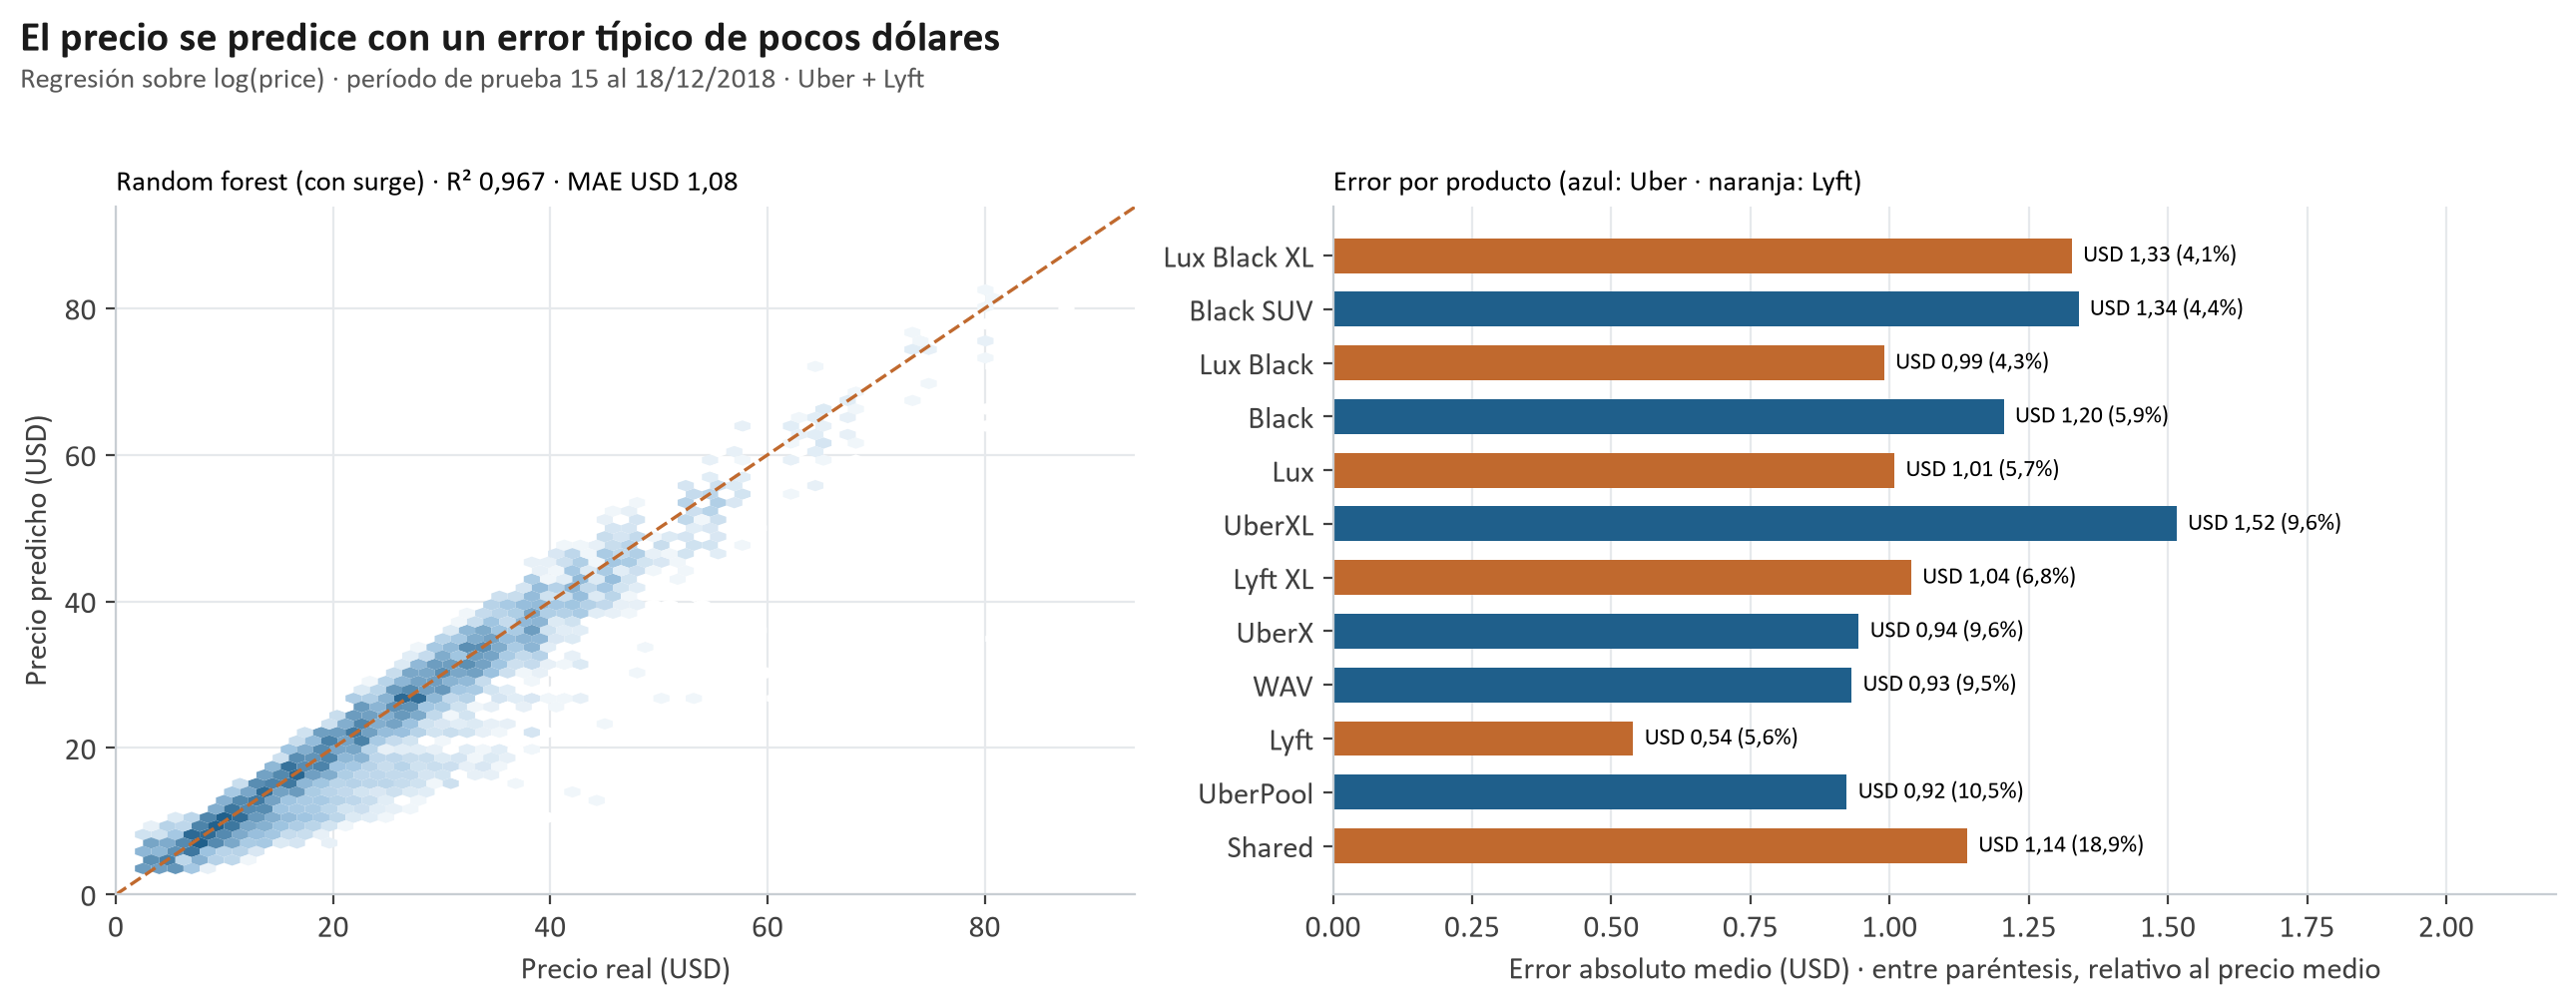

In [6]:
# @title Figura 1 · Precio real vs predicho { display-mode: "form" }
figura("fig01_precio_real_vs_predicho.png")

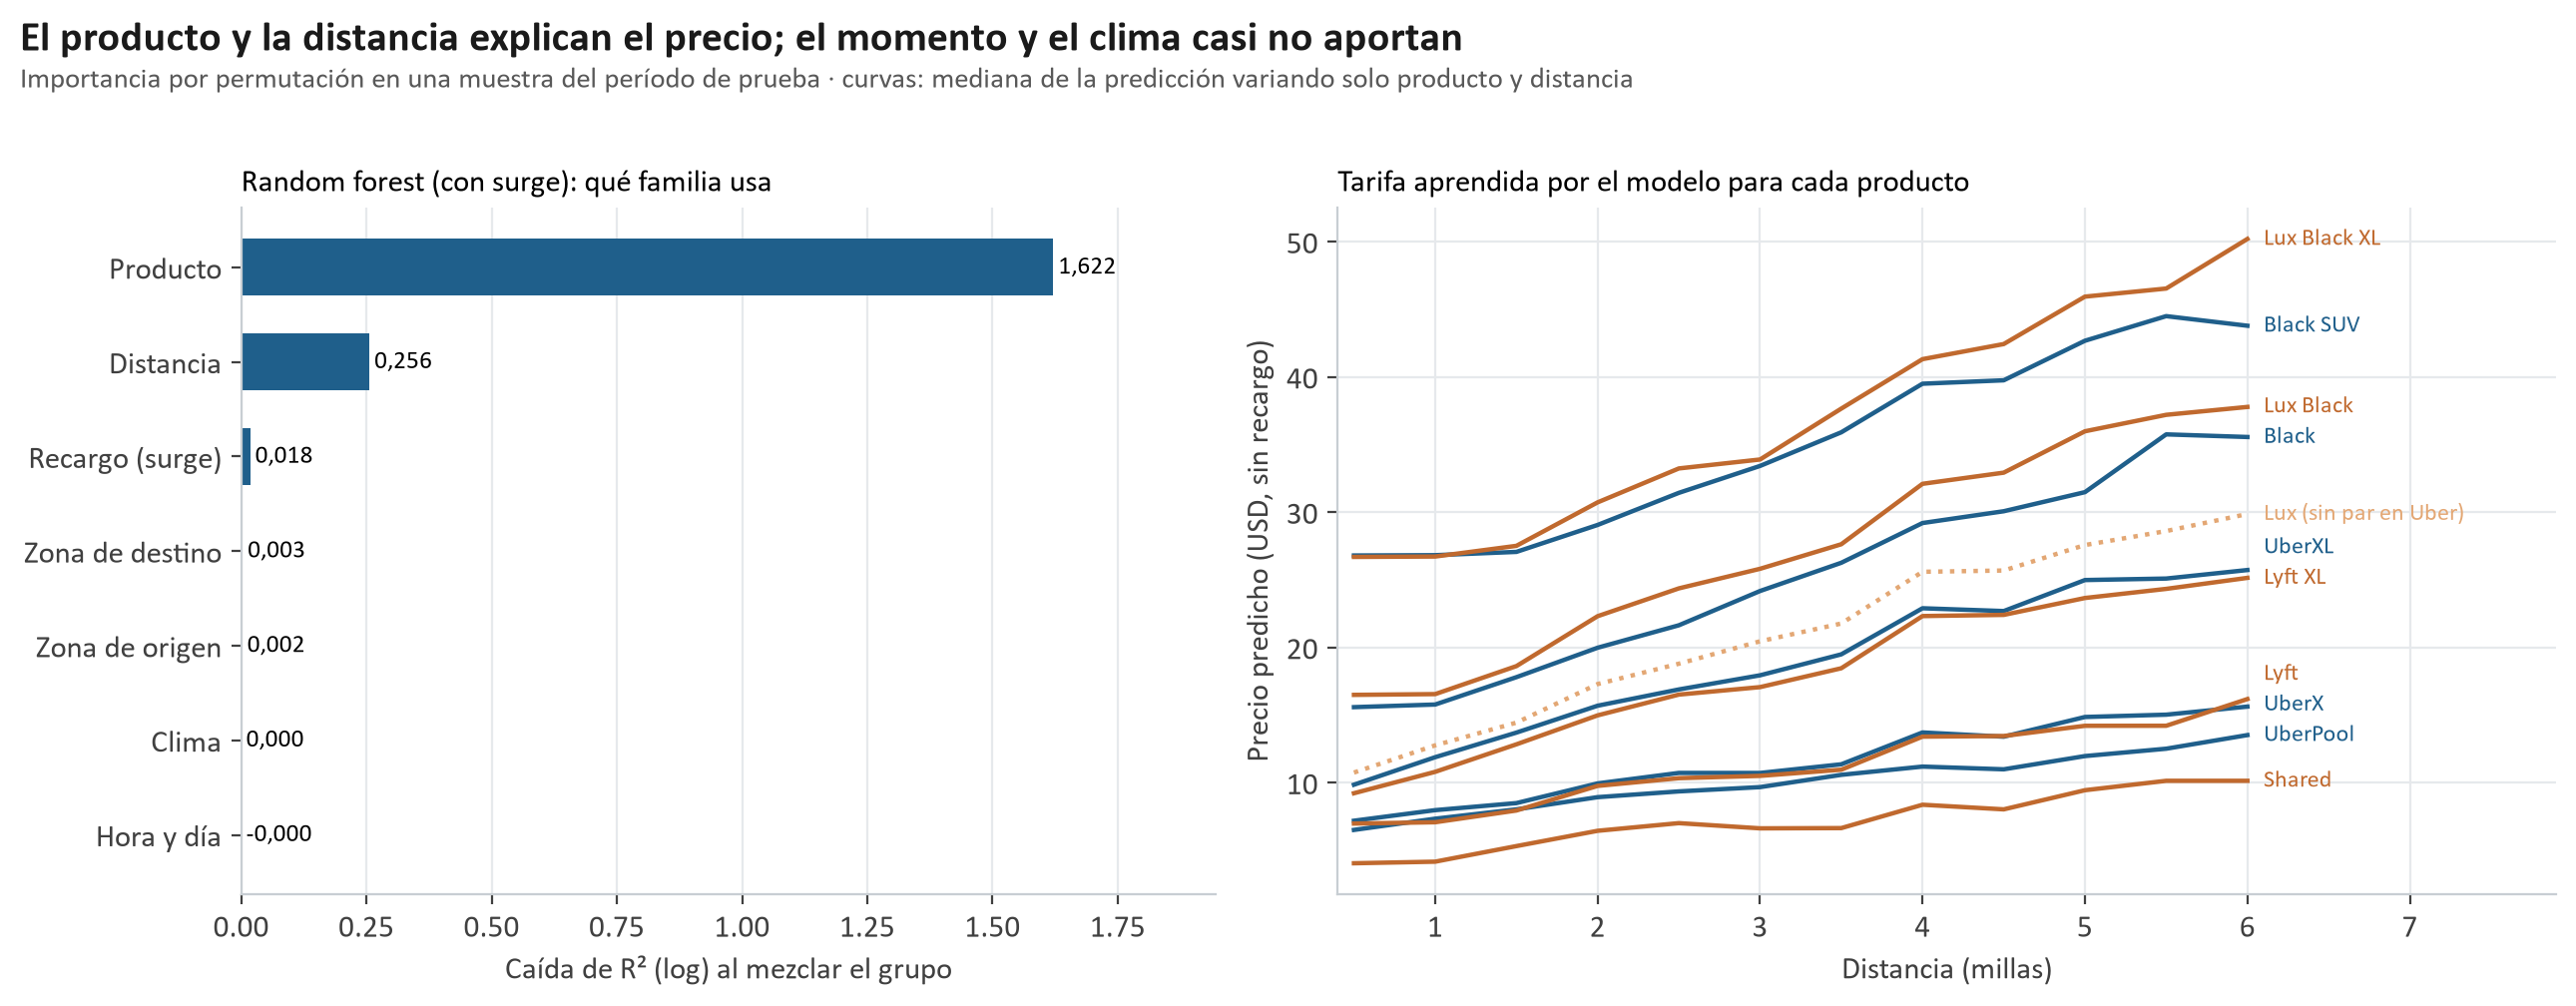

- **El producto y la distancia explican el precio** (H1). La hora y el clima no aportan.
- **Uber vs Lyft (H2):** Lyft es más barato en los económicos (Shared -29%) y más caro en los Black (+8%).

In [7]:
# @title Figura 2 · Qué usa el modelo y tarifa de cada producto { display-mode: "form" }
figura("fig02_precio_importancia_y_tarifas.png")
h2 = {h["nivel"]: h["dif_lyft_vs_uber"] for h in M["B_h2"]}
md(f"- **El producto y la distancia explican el precio** (H1). La hora y el clima no aportan.\n"
   f"- **Uber vs Lyft (H2):** Lyft es más barato en los económicos (Shared {pct(h2['Compartido'], 0)}) "
   f"y más caro en los Black ({'+' if h2['Black'] > 0 else ''}{pct(h2['Black'], 0)}).")

## 6 · Objetivo 2 · ¿Tiene recargo? El problema de la accuracy

Solo **8,2%** de las cotizaciones tiene recargo (1 de cada 12).

La **accuracy** es el % de predicciones correctas. Un "modelo" que dice **siempre "sin recargo"** tiene **91,7% de accuracy**… y no detecta ningún recargo. Por eso la accuracy se lee **siempre contra estas referencias**:

In [8]:
# @title Líneas base: lo que tiene que superar un modelo { display-mode: "form" }
filas = [[b["modelo"], pct(b["accuracy"]), pct(b["accuracy_balanceada"]), pct(b["recall"]), pct(b["precision"]), num(b["pr_auc"])]
         for b in M["A_lineas_base"]]
tabla(pd.DataFrame(filas, columns=["Referencia", "Accuracy", "Accuracy balanceada", "Recall", "Precisión", "PR-AUC"]))
z = BASE["Tasa histórica de la zona de origen"]
md(f"- **Accuracy balanceada:** promedio del acierto en cada clase (50% = azar).\n"
   f"- **Recall:** qué % de los recargos detecta. **Precisión:** de las alertas, cuántas son recargos reales.\n"
   f"- La referencia más exigente es la **tasa de la zona de origen**, sin ningún modelo: ya logra PR-AUC {num(z['pr_auc'])}.")

Referencia,Accuracy,Accuracy balanceada,Recall,Precisión,PR-AUC
Siempre 'sin recargo',"91,7%","50,0%","0,0%","0,0%","0,083"
Siempre 'con recargo',"8,3%","50,0%","100,0%","8,3%","0,083"
Azar con la tasa real,"85,0%","50,1%","8,2%","8,4%","0,083"
Tasa histórica de la zona de origen,"66,0%","58,7%","50,0%","12,2%","0,118"


- **Accuracy balanceada:** promedio del acierto en cada clase (50% = azar).
- **Recall:** qué % de los recargos detecta. **Precisión:** de las alertas, cuántas son recargos reales.
- La referencia más exigente es la **tasa de la zona de origen**, sin ningún modelo: ya logra PR-AUC 0,118.

### Demostración en vivo: el mismo árbol, sin balancear y balanceado (umbral 0,5)

Árbol,Accuracy,Accuracy balanceada,Recall (recargos detectados),Precisión
Sin balancear,"91,7%","50,0%","0,0%","0,0%"
Con pesos de clase,"50,7%","62,8%","77,3%","11,9%"


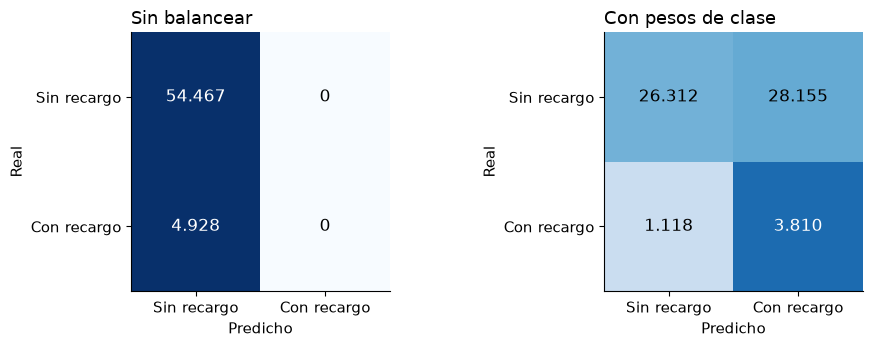

In [9]:
# @title Entrenar y comparar (≈10 segundos) { display-mode: "form" }
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score, precision_score, confusion_matrix

surge = pd.read_csv(DATOS / "datasets modelado" / "dataset_modelado_surge.zip")
predictoras = [c for c in surge.columns if c not in ("id", "datetime_local", "fecha", "particion", "has_surge", "ruta")]
tr, te = surge[surge["particion"] == "train"], surge[surge["particion"] == "test"]
resultados, matrices = [], []
for etiqueta, tecnica, pesos in [("Sin balancear", "sin", None), ("Con pesos de clase", "pesos", "balanced")]:
    params = M["A_tuning"]["Árbol de decisión"][tecnica]["params"]
    arbol = DecisionTreeClassifier(**params, class_weight=pesos, random_state=42).fit(tr[predictoras], tr["has_surge"])
    pred = arbol.predict(te[predictoras])
    resultados.append([etiqueta, pct(accuracy_score(te["has_surge"], pred)), pct(balanced_accuracy_score(te["has_surge"], pred)),
                       pct(recall_score(te["has_surge"], pred)), pct(precision_score(te["has_surge"], pred, zero_division=0))])
    matrices.append((etiqueta, confusion_matrix(te["has_surge"], pred)))
tabla(pd.DataFrame(resultados, columns=["Árbol", "Accuracy", "Accuracy balanceada", "Recall (recargos detectados)", "Precisión"]))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (etiqueta, cm) in zip(axes, matrices):
    ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}".replace(",", "."), ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] / cm[i].sum() > 0.6 else "black")
    ax.set_xticks([0, 1], ["Sin recargo", "Con recargo"]); ax.set_yticks([0, 1], ["Sin recargo", "Con recargo"])
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); ax.set_title(etiqueta, loc="left")
plt.tight_layout(); plt.show()

**Conclusión:** con el umbral estándar de 0,5, el árbol sin balancear casi nunca avisa de un recargo: accuracy altísima, recall casi nulo. Balanceando, la accuracy baja pero **la accuracy balanceada y el recall suben**. Ojo: esto pasa con el umbral 0,5. En la sección 7 vemos qué pasa cuando el umbral también se ajusta.

## 7 · Balanceo de clases: cuatro técnicas

El balanceo **no cambia la realidad**: cambia cómo aprende el modelo, para que no ignore los recargos. Se aplica **solo al entrenamiento**; la validación y la prueba mantienen la proporción real.

| Técnica | Qué hace | Filas para entrenar | % con recargo |
|---|---|---|---|
| Sin balanceo | Datos tal cual | 196.558 | 8,2% |
| Submuestreo | Descarta cotizaciones sin recargo | 32.094 | 50% |
| SMOTE | Inventa recargos "sintéticos" | 361.022 | 50% |
| **Pesos de clase** | No cambia los datos: equivocarse en un recargo "cuesta" 11 veces más | 196.558 | 8,2% |

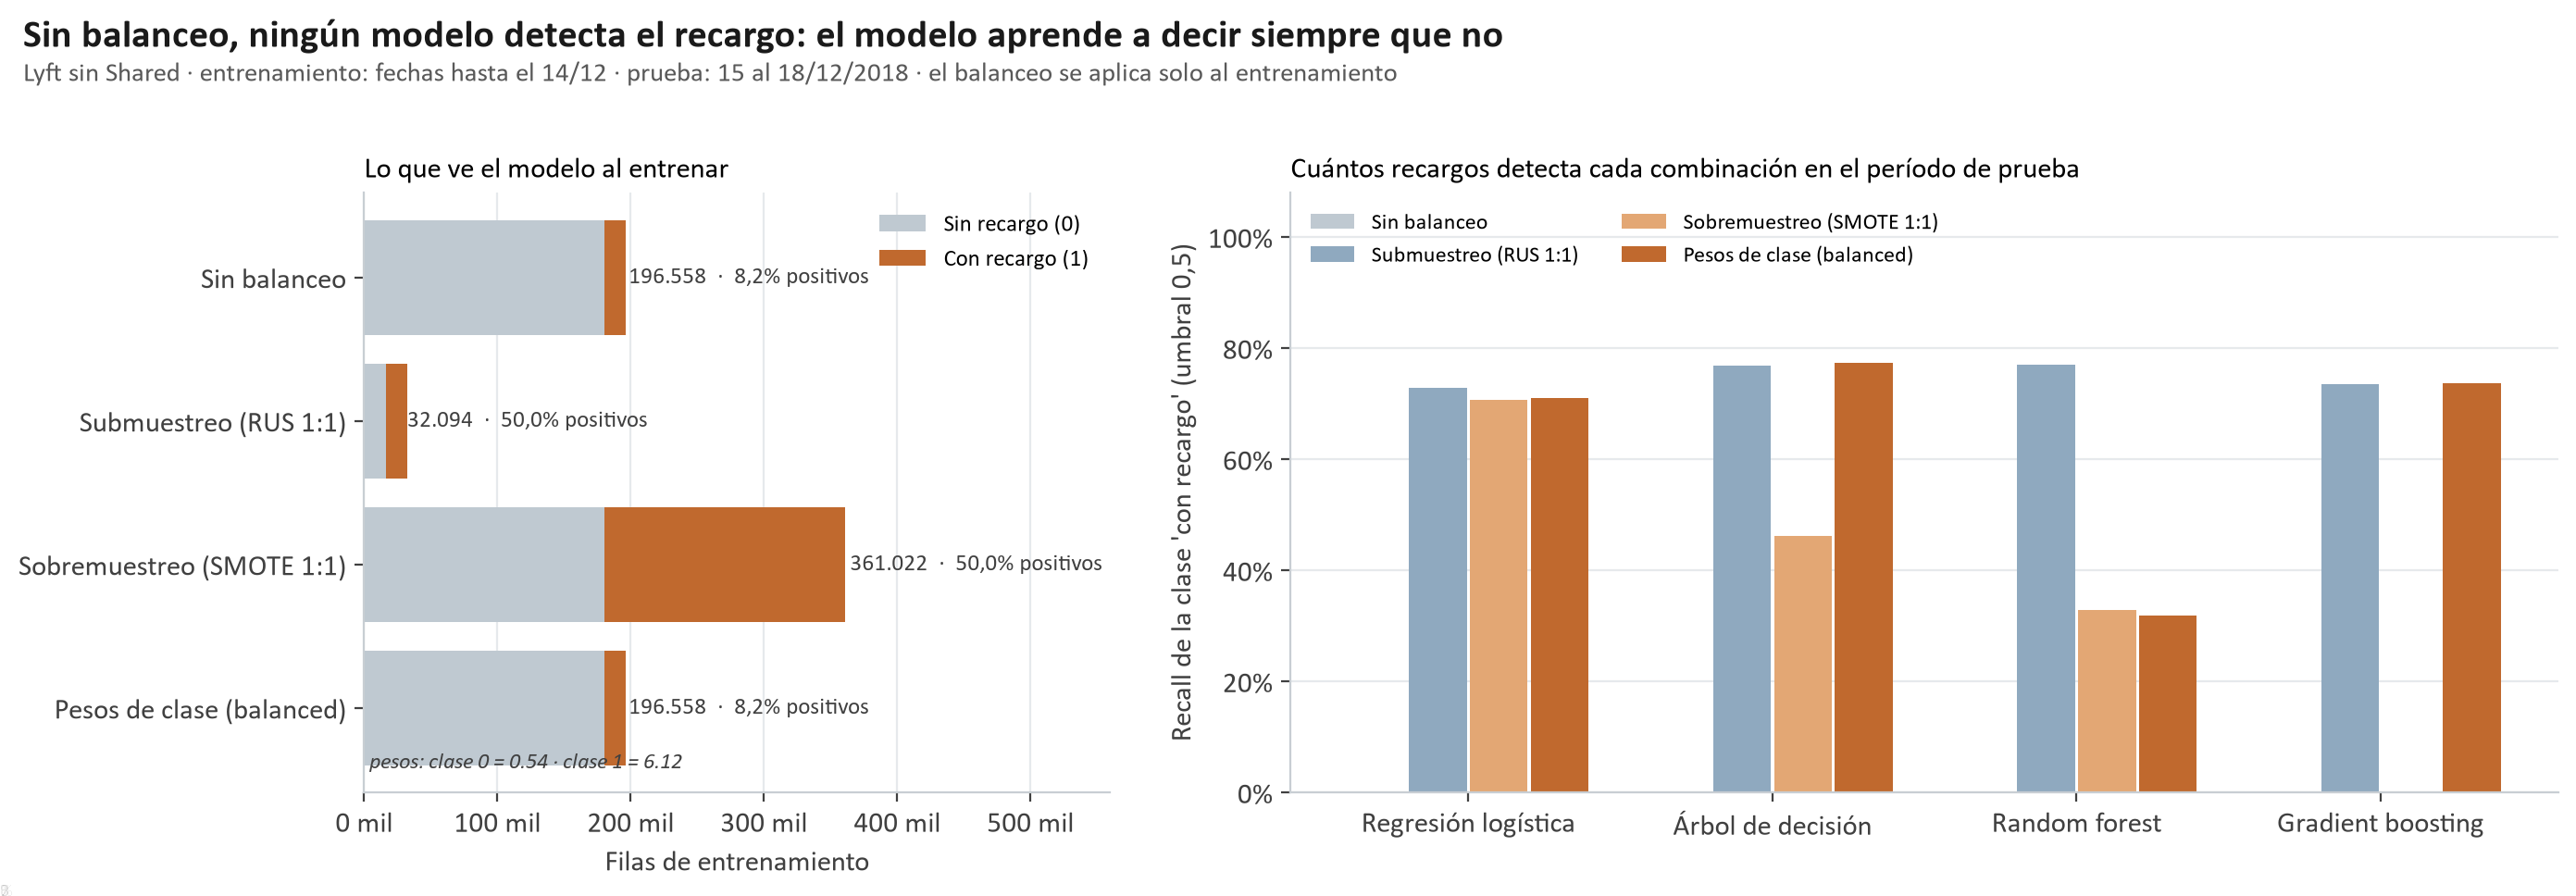

In [10]:
# @title Figura 4 · Cuántos recargos detecta cada combinación (umbral 0,5) { display-mode: "form" }
figura("fig04_recargo_balanceo.png")

In [11]:
# @title ¿Hace falta balancear si también se ajusta el umbral? { display-mode: "form" }
filas = []
tec = M["A_tecnica_elegida"]["nombre"].split(" (")[0]
for r in M["A_sin_balanceo_umbral"]:
    for etiqueta, x in [("Sin balanceo", r["sin_balanceo"]), (tec, r["tecnica_elegida"])]:
        filas.append([r["modelo"], etiqueta, num(x["umbral"], 2), pct(x["recall"]), pct(x["precision"]), num(x["pr_auc"]),
                      f"USD {x['beneficio_1000']:.0f}"])
tabla(pd.DataFrame(filas, columns=["Modelo", "Técnica", "Umbral", "Recall", "Precisión", "PR-AUC", "Beneficio / 1.000"]))
mejor = M["A_tecnica_elegida"]["mejor_por_modelo"]
md(f"- **Balancear no mejora el ranking, mueve el umbral:** el PR-AUC casi no cambia. Sin balanceo el modelo también detecta recargos "
   f"si el umbral se baja (por eso sin balanceo los umbrales son tan chicos).\n"
   f"- En validación, la mejor técnica fue: " + "; ".join(f"{m.lower()}, {t.split(' (')[0].lower()}" for m, t in mejor.items()) + ".\n"
   f"- **Elegimos {tec.lower()}** porque formó el mejor par en validación ({E.lower()} + {tec.lower()}) y usa todos los datos reales.\n"
   f"- **SMOTE** inventa cotizaciones imposibles (\"0,4 de Back Bay\") y no ayuda. **Submuestreo** tira el 91% de los datos.")

Modelo,Técnica,Umbral,Recall,Precisión,PR-AUC,Beneficio / 1.000
Regresión logística,Sin balanceo,"0,10","64,5%","12,1%","0,121",USD 26
Regresión logística,Pesos de clase,"0,54","63,5%","12,2%","0,121",USD 29
Árbol de decisión,Sin balanceo,"0,14","28,4%","15,2%","0,139",USD 51
Árbol de decisión,Pesos de clase,"0,63","21,1%","16,0%","0,138",USD 43
Random forest,Sin balanceo,"0,12","42,8%","14,2%","0,138",USD 61
Random forest,Pesos de clase,"0,44","53,3%","13,3%","0,142",USD 55
Gradient boosting,Sin balanceo,"0,11","49,6%","13,5%","0,144",USD 54
Gradient boosting,Pesos de clase,"0,57","51,4%","13,5%","0,140",USD 56


- **Balancear no mejora el ranking, mueve el umbral:** el PR-AUC casi no cambia. Sin balanceo el modelo también detecta recargos si el umbral se baja (por eso sin balanceo los umbrales son tan chicos).
- En validación, la mejor técnica fue: regresión logística, sin balanceo; árbol de decisión, sin balanceo; random forest, sin balanceo; gradient boosting, pesos de clase.
- **Elegimos pesos de clase** porque formó el mejor par en validación (gradient boosting + pesos de clase) y usa todos los datos reales.
- **SMOTE** inventa cotizaciones imposibles ("0,4 de Back Bay") y no ayuda. **Submuestreo** tira el 91% de los datos.

## 8 · Modelo final y su accuracy

Pesos de clase y un **umbral de decisión** elegido con la matriz de beneficio en validación (no en la prueba).

In [12]:
# @title Métricas en los 4 días de prueba { display-mode: "form" }
filas = []
for m, r in M["A_finales"].items():
    r = r["umbral_opt"]
    filas.append([m + ("  ★" if m == E else ""), num(r["umbral"], 2), pct(r["accuracy"]), pct(r["accuracy_balanceada"]),
                  pct(r["recall"]), pct(r["precision"]), num(r["roc_auc"]), num(r["pr_auc"])])
filas.sort(key=lambda f: "★" not in f[0])
for b in M["A_lineas_base"]:
    if b["modelo"] in ("Siempre 'sin recargo'", "Tasa histórica de la zona de origen"):
        filas.append(["Referencia: " + b["modelo"].lower(), "–", pct(b["accuracy"]), pct(b["accuracy_balanceada"]),
                      pct(b["recall"]), pct(b["precision"]), num(b["roc_auc"]), num(b["pr_auc"])])
tabla(pd.DataFrame(filas, columns=["Modelo", "Umbral", "Accuracy", "Accuracy balanceada", "Recall", "Precisión", "ROC-AUC", "PR-AUC"]))

Modelo,Umbral,Accuracy,Accuracy balanceada,Recall,Precisión,ROC-AUC,PR-AUC
Gradient boosting ★,"0,57","68,6%","60,8%","51,4%","13,5%","0,676","0,140"
Regresión logística,"0,54","59,1%","61,1%","63,5%","12,2%","0,650","0,121"
Árbol de decisión,"0,63","84,3%","55,5%","21,1%","16,0%","0,672","0,138"
Random forest,"0,44","67,4%","61,0%","53,3%","13,3%","0,675","0,142"
Referencia: siempre 'sin recargo',–,"91,7%","50,0%","0,0%","0,0%","0,500","0,083"
Referencia: tasa histórica de la zona de origen,–,"66,0%","58,7%","50,0%","12,2%","0,649","0,118"


In [13]:
# @title Niveles de certeza del modelo elegido (intervalos de confianza del 95%) { display-mode: "form" }
nombres = {"accuracy": "Accuracy", "accuracy_balanceada": "Accuracy balanceada", "precision": "Precisión", "recall": "Recall",
           "roc_auc": "ROC-AUC", "pr_auc": "PR-AUC", "ventaja_pr_auc_sobre_zona": "Ventaja de PR-AUC sobre la tasa de la zona"}
filas = []
for k, nombre in nombres.items():
    d = IC[k]
    f = pct if k in ("accuracy", "accuracy_balanceada", "precision", "recall") else num
    filas.append([nombre, f(d["valor"]), f"{f(d['bajo'])} a {f(d['alto'])}"])
tabla(pd.DataFrame(filas, columns=["Métrica", "Valor", "IC 95%"]))
v = IC["ventaja_pr_auc_sobre_zona"]
md(f"Los intervalos salen de **{miles(M['A_ic95']['replicas'])} remuestreos por bootstrap de las {M['A_ic95']['bloques']} horas** del período de prueba "
   f"(las cotizaciones de una misma hora comparten recargo, así que se remuestrean horas completas). "
   + ("La ventaja sobre la tasa de la zona es **positiva en todo el intervalo**: el modelo aprende algo más que \"dónde sube\"."
      if v["bajo"] > 0 else
      "La ventaja sobre la tasa de la zona es chica y el intervalo **toca el cero**: con estos datos, el modelo apenas mejora a la regla simple por zona."))

Métrica,Valor,IC 95%
Accuracy,"68,6%","67,3% a 69,8%"
Accuracy balanceada,"60,8%","59,4% a 62,1%"
Precisión,"13,5%","12,7% a 14,3%"
Recall,"51,4%","48,4% a 54,5%"
ROC-AUC,"0,676","0,663 a 0,689"
PR-AUC,"0,140","0,132 a 0,150"
Ventaja de PR-AUC sobre la tasa de la zona,"0,022","0,015 a 0,029"


Los intervalos salen de **1.000 remuestreos por bootstrap de las 87 horas** del período de prueba (las cotizaciones de una misma hora comparten recargo, así que se remuestrean horas completas). La ventaja sobre la tasa de la zona es **positiva en todo el intervalo**: el modelo aprende algo más que "dónde sube".

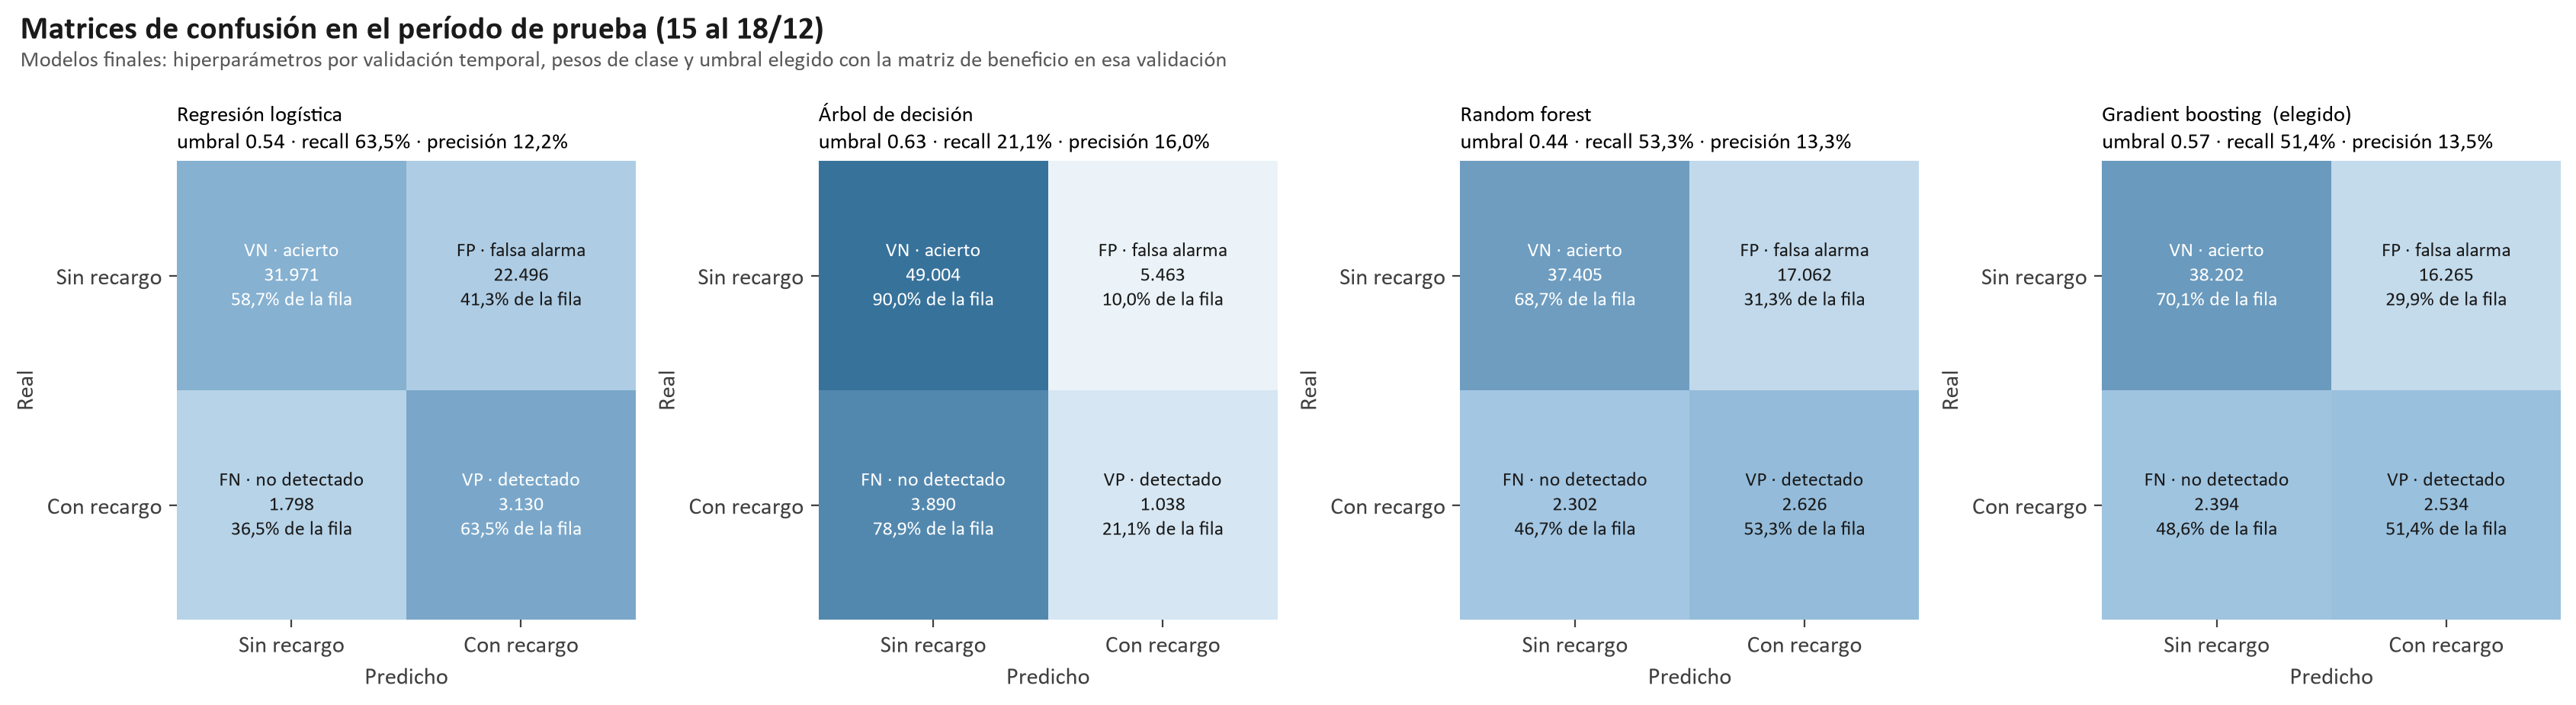

**Cómo leer la matriz del modelo elegido (gradient boosting):**

| | Predijo **sin recargo** | Predijo **con recargo** |
|---|---|---|
| **Real: sin recargo** | **VN = 38.202** · acierto | **FP = 16.265** · falsa alarma |
| **Real: con recargo** | **FN = 2.394** · recargo no detectado | **VP = 2.534** · recargo detectado |

- **Accuracy** = (VP + VN) / total = **68,6%**, contra 91,7% de decir siempre que no.
- **Precisión** = VP / (VP + FP) = **13,5%**: de cada 100 alertas, 13 son recargos reales (el azar acierta 8).
- **Recall** = VP / (VP + FN) = **51,4%** de los recargos detectados.
- **Accuracy balanceada 60,8%** (azar = 50%). El modelo avisa en el 31,7% de las cotizaciones.

In [14]:
# @title Figura 5 · Matrices de confusión { display-mode: "form" }
figura("fig05_recargo_matrices_confusion.png")
md(f"""**Cómo leer la matriz del modelo elegido ({E.lower()}):**

| | Predijo **sin recargo** | Predijo **con recargo** |
|---|---|---|
| **Real: sin recargo** | **VN = {miles(FIN['tn'])}** · acierto | **FP = {miles(FIN['fp'])}** · falsa alarma |
| **Real: con recargo** | **FN = {miles(FIN['fn'])}** · recargo no detectado | **VP = {miles(FIN['tp'])}** · recargo detectado |

- **Accuracy** = (VP + VN) / total = **{pct(FIN['accuracy'])}**, contra 91,7% de decir siempre que no.
- **Precisión** = VP / (VP + FP) = **{pct(FIN['precision'])}**: de cada 100 alertas, {FIN['precision'] * 100:.0f} son recargos reales (el azar acierta 8).
- **Recall** = VP / (VP + FN) = **{pct(FIN['recall'])}** de los recargos detectados.
- **Accuracy balanceada {pct(FIN['accuracy_balanceada'])}** (azar = 50%). El modelo avisa en el {pct(FIN['alertas'])} de las cotizaciones.""")

## 9 · Análisis con la matriz de beneficio

¿Qué nos conviene más: **evitar falsas alarmas** o **no perder recargos**? La matriz de beneficio le pone un valor en dólares a cada casilla de la matriz de confusión y elige el umbral que más conviene.

In [15]:
# @title La matriz de beneficio { display-mode: "form" }
md(f"""| | Predice **sin recargo** | Predice **con recargo** (aviso) |
|---|---|---|
| **Real: sin recargo** | VN · USD 0 | FP · **−{usd(MB['costo_falsa_alarma'])}** (compara o espera sin necesidad) |
| **Real: con recargo** | FN · USD 0 (paga el recargo, igual que sin modelo) | VP · **+{usd(MB['vp'])}** (evita el recargo y pierde el tiempo de comparar) |

- **Recargo medio evitado: {usd(MB['recargo_medio'])}** (medido en las cotizaciones con recargo del entrenamiento).
- **Costo de una falsa alarma: {usd(MB['costo_falsa_alarma'])}**, unos 5 minutos de comparar o esperar. Es un **supuesto** del equipo: por eso mostramos la sensibilidad.
- **Regla que sale de la matriz:** conviene avisar si la probabilidad de recargo supera costo / recargo = **{pct(MB['precision_minima'])}**.""")

| | Predice **sin recargo** | Predice **con recargo** (aviso) |
|---|---|---|
| **Real: sin recargo** | VN · USD 0 | FP · **−USD 1,00** (compara o espera sin necesidad) |
| **Real: con recargo** | FN · USD 0 (paga el recargo, igual que sin modelo) | VP · **+USD 7,73** (evita el recargo y pierde el tiempo de comparar) |

- **Recargo medio evitado: USD 8,73** (medido en las cotizaciones con recargo del entrenamiento).
- **Costo de una falsa alarma: USD 1,00**, unos 5 minutos de comparar o esperar. Es un **supuesto** del equipo: por eso mostramos la sensibilidad.
- **Regla que sale de la matriz:** conviene avisar si la probabilidad de recargo supera costo / recargo = **11,4%**.

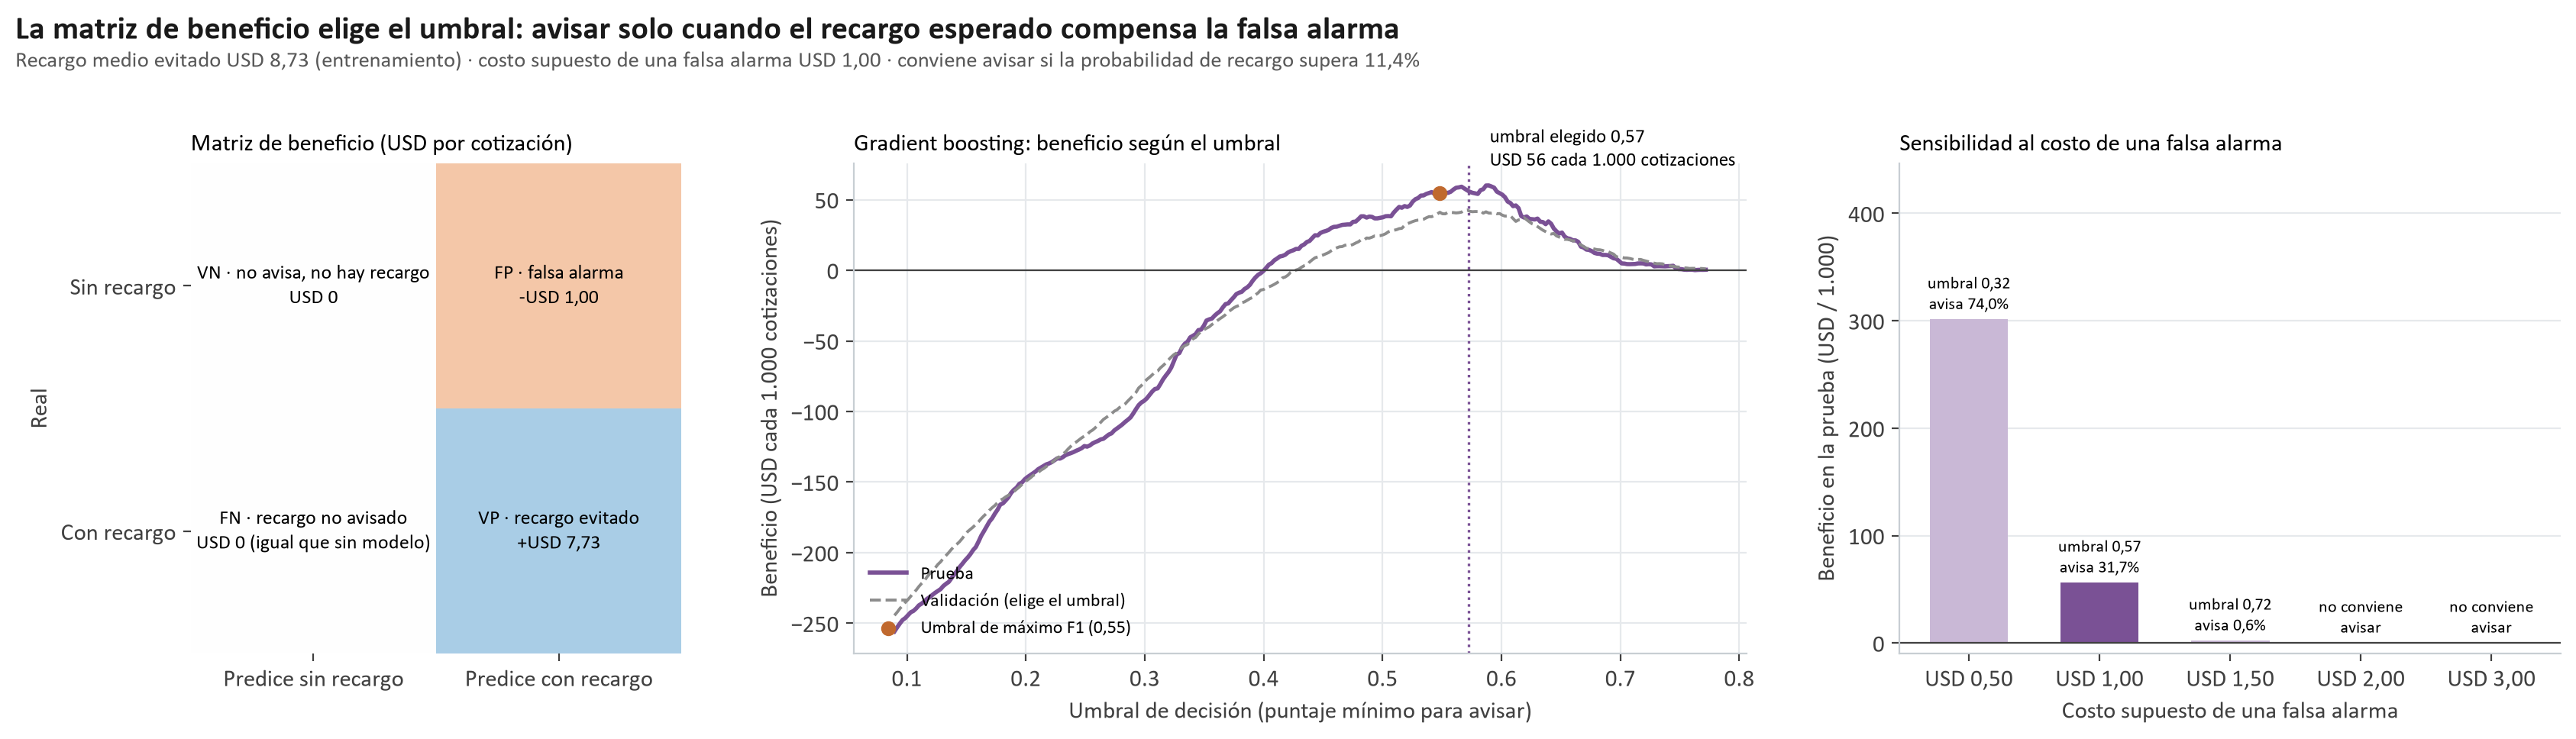

- Con la matriz, el umbral del modelo elegido es **0,57**: avisa en el 31,7% de las cotizaciones, con precisión 13,5% y recall 51,4%, y gana **USD 56 cada 1.000 cotizaciones**.
- Con el umbral de máximo F1 (0,55) avisaba en el 38,5%, con precisión 13,1%: beneficio **USD 55**. **Avisaba de más.**

In [16]:
# @title Figura 6 · Beneficio según el umbral y sensibilidad al costo { display-mode: "form" }
figura("fig06_recargo_matriz_beneficio.png")
md(f"- Con la matriz, el umbral del modelo elegido es **{num(FIN['umbral'], 2)}**: avisa en el {pct(FIN['alertas'])} de las cotizaciones, "
   f"con precisión {pct(FIN['precision'])} y recall {pct(FIN['recall'])}, y gana **USD {FIN['beneficio_1000']:.0f} cada 1.000 cotizaciones**.\n"
   f"- Con el umbral de máximo F1 ({num(FIN_F1['umbral'], 2)}) avisaba en el {pct(FIN_F1['alertas'])}, con precisión {pct(FIN_F1['precision'])}: "
   f"beneficio **USD {FIN_F1['beneficio_1000']:.0f}**. **Avisaba de más.**")

In [17]:
# @title Sensibilidad: ¿qué pasa si la falsa alarma cuesta más o menos? { display-mode: "form" }
filas = [[usd(s["costo"]), pct(s["precision_minima"]), "no avisar" if s["alertas"] == 0 else num(s["umbral"], 2),
          pct(s["alertas"]), pct(s["recall"]), pct(s["precision"]) if s["alertas"] > 0 else "–", f"USD {s['beneficio_1000']:.0f}"]
         for s in M["A_sensibilidad_costo"]]
tabla(pd.DataFrame(filas, columns=["Costo de una falsa alarma", "Precisión mínima", "Umbral", "Avisa en", "Recall", "Precisión", "Beneficio / 1.000"]))

Costo de una falsa alarma,Precisión mínima,Umbral,Avisa en,Recall,Precisión,Beneficio / 1.000
"USD 0,50","5,7%","0,32","74,0%","92,7%","10,4%",USD 301
"USD 1,00","11,4%","0,57","31,7%","51,4%","13,5%",USD 56
"USD 1,50","17,2%","0,72","0,6%","1,5%","21,5%",USD 2
"USD 2,00","22,9%",no avisar,"0,0%","0,0%",–,USD 0
"USD 3,00","34,3%",no avisar,"0,0%","0,0%",–,USD 0


In [18]:
# @title Hasta dónde podemos bajar los falsos negativos (y cuánto cuesta en falsos positivos) { display-mode: "form" }
filas = [[pct(p["recall_objetivo"], 0), num(p["umbral"], 2), pct(p["recall"]), miles(p["fn"]), miles(p["fp"]), pct(p["precision"]),
          pct(p["accuracy"]), f"USD {p['beneficio_1000']:.0f}"] for p in M["A_puntos_operacion"]]
tabla(pd.DataFrame(filas, columns=["Recargos a detectar", "Umbral", "Recall real", "FN", "FP", "Precisión", "Accuracy", "Beneficio / 1.000"]))
pmax = M["A_precision_maxima"]["precision"]
md(f"""**En qué conviene enfocarse:**

- **En la precisión (menos falsas alarmas), no en detectar todos los recargos.** Para detectar el 90% de los recargos hay que avisar casi siempre, y las falsas alarmas se comen el beneficio.
- **El techo del dominio:** aun en su mejor tramo, el modelo no supera ~{pct(pmax, 0)} de precisión. El recargo depende de la oferta y la demanda en tiempo real, que no está en el dataset.
- **Si una falsa alarma le cuesta al pasajero USD 2 o más, no conviene avisar nunca.** El modelo sirve para avisos de bajo costo (por ejemplo, "conviene comparar con Uber"), no para decisiones caras.""")

Recargos a detectar,Umbral,Recall real,FN,FP,Precisión,Accuracy,Beneficio / 1.000
90%,"0,27","96,5%",173,43.508,"9,9%","26,5%",USD -113
80%,"0,38","87,0%",639,34.152,"11,2%","41,4%",USD -17
70%,"0,45","81,4%",919,29.423,"12,0%","48,9%",USD 27
60%,"0,50","74,6%",1.251,26.289,"12,3%","53,6%",USD 36
50%,"0,54","63,4%",1.802,20.887,"13,0%","61,8%",USD 55
40%,"0,57","51,3%",2.400,16.229,"13,5%","68,6%",USD 56
30%,"0,60","35,2%",3.193,10.210,"14,5%","77,4%",USD 54
20%,"0,62","18,4%",4.020,4.905,"15,6%","85,0%",USD 36
10%,"0,66","8,2%",4.525,1.734,"18,9%","89,5%",USD 23


**En qué conviene enfocarse:**

- **En la precisión (menos falsas alarmas), no en detectar todos los recargos.** Para detectar el 90% de los recargos hay que avisar casi siempre, y las falsas alarmas se comen el beneficio.
- **El techo del dominio:** aun en su mejor tramo, el modelo no supera ~20% de precisión. El recargo depende de la oferta y la demanda en tiempo real, que no está en el dataset.
- **Si una falsa alarma le cuesta al pasajero USD 2 o más, no conviene avisar nunca.** El modelo sirve para avisos de bajo costo (por ejemplo, "conviene comparar con Uber"), no para decisiones caras.

## 10 · Curva ROC y AUC

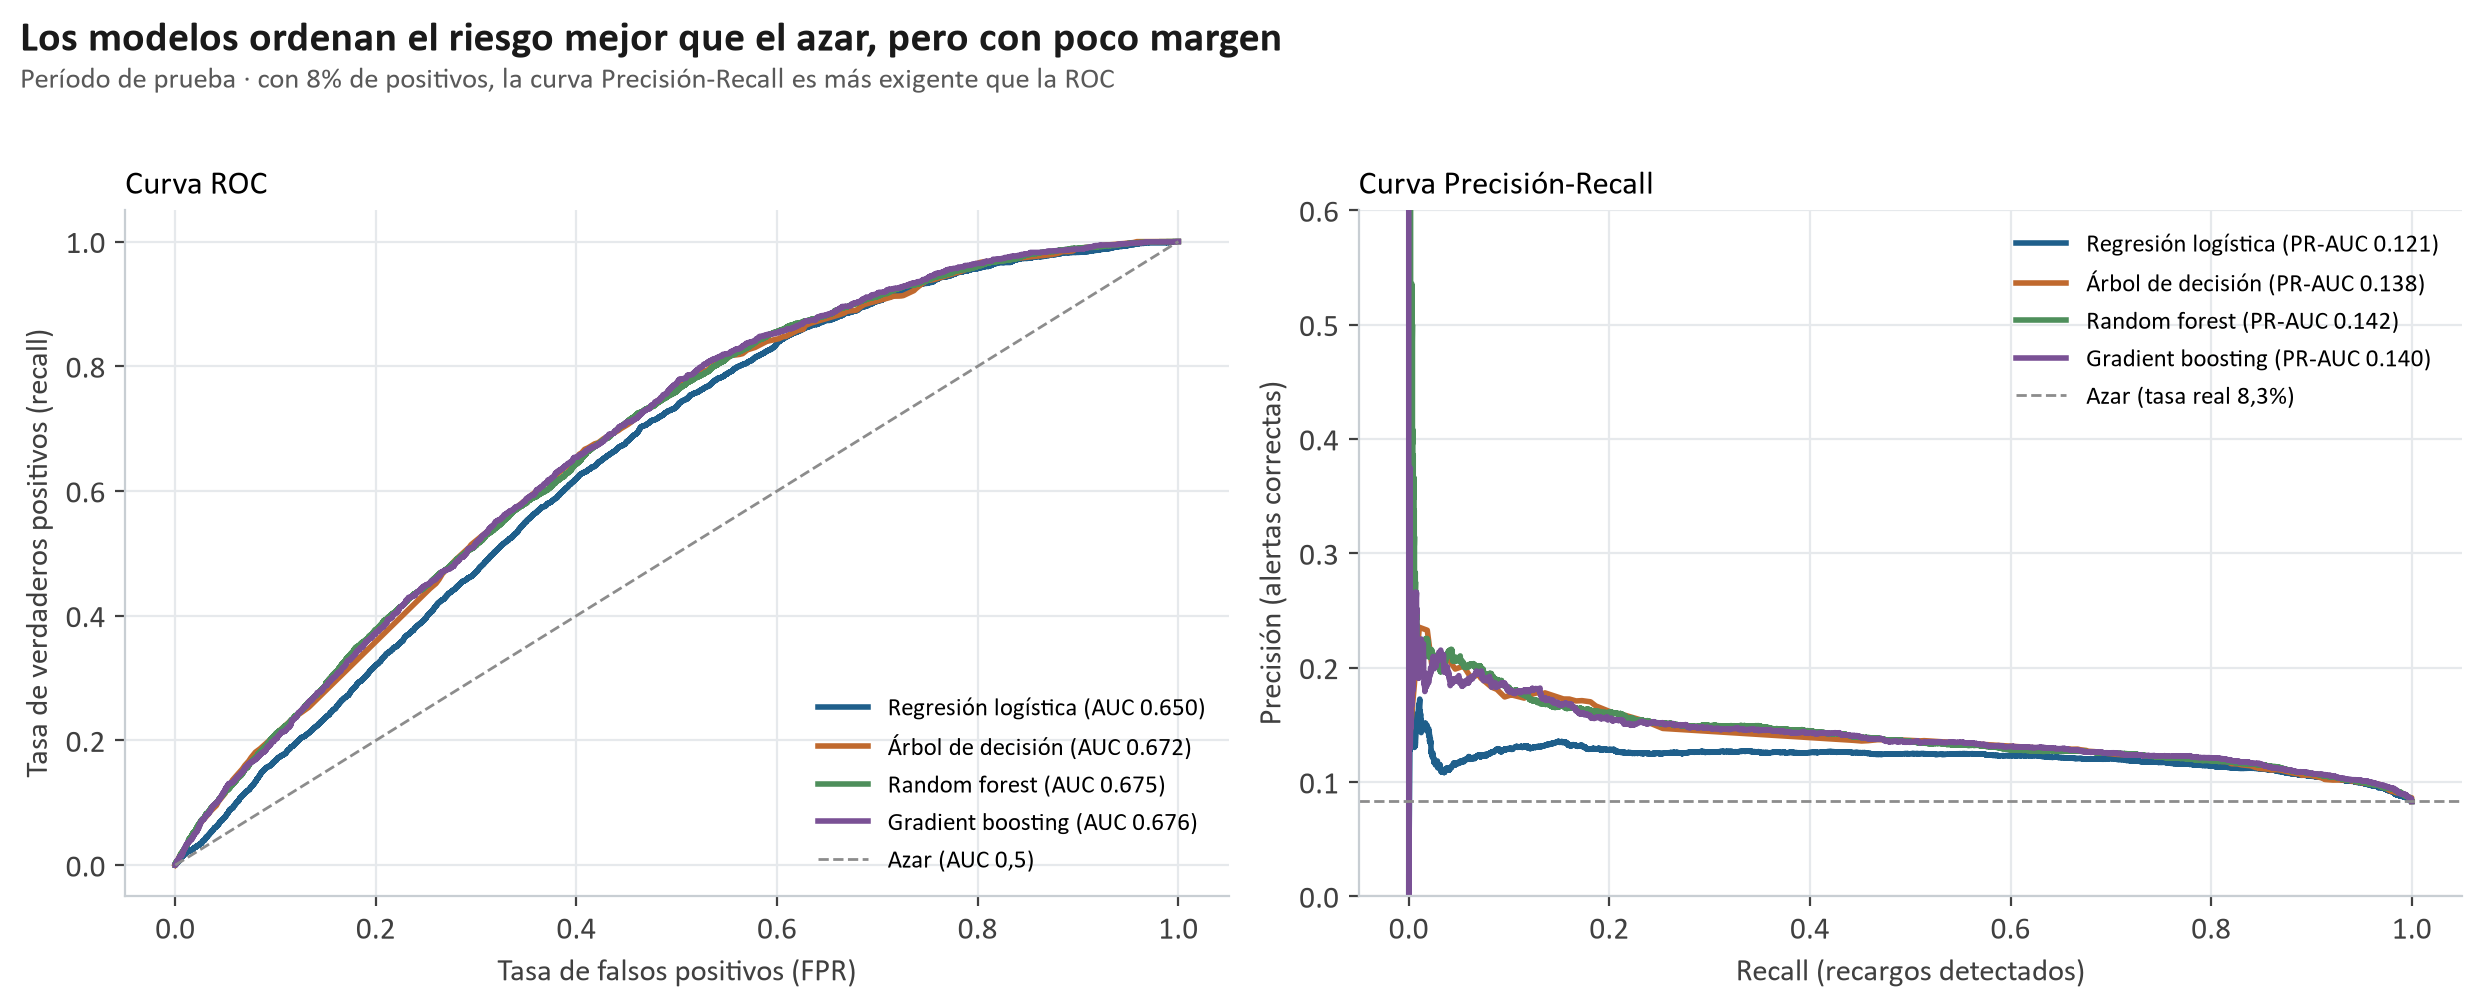

**Cómo leer la curva ROC:** cada punto es un umbral. El eje X es la tasa de falsas alarmas (FP / sin recargo) y el eje Y, el recall.
La diagonal es el azar (AUC = 0,5); un modelo perfecto llega a la esquina superior izquierda (AUC = 1).

- **ROC-AUC entre 0,650 y 0,676:** los cuatro modelos están por encima del azar, pero lejos de un clasificador fuerte.
  Significa que si se toma al azar una cotización con recargo y una sin recargo, el modelo le da más puntaje a la que tiene recargo
  el 68% de las veces (gradient boosting).
- **IC 95% del ROC-AUC del modelo elegido:** 0,663 a 0,689.
- **La curva Precisión-Recall** es más exigente con 8% de positivos: la precisión se mantiene baja en casi todo el recorrido. El recargo es difícil de anticipar con estos datos.

In [19]:
# @title Figura 7 · Curvas ROC y Precisión-Recall { display-mode: "form" }
figura("fig07_recargo_curvas_roc_pr.png")
rocs = {m: r["umbral_opt"]["roc_auc"] for m, r in M["A_finales"].items()}
md(f"""**Cómo leer la curva ROC:** cada punto es un umbral. El eje X es la tasa de falsas alarmas (FP / sin recargo) y el eje Y, el recall.
La diagonal es el azar (AUC = 0,5); un modelo perfecto llega a la esquina superior izquierda (AUC = 1).

- **ROC-AUC entre {num(min(rocs.values()))} y {num(max(rocs.values()))}:** los cuatro modelos están por encima del azar, pero lejos de un clasificador fuerte.
  Significa que si se toma al azar una cotización con recargo y una sin recargo, el modelo le da más puntaje a la que tiene recargo
  el {pct(rocs[E], 0)} de las veces ({E.lower()}).
- **IC 95% del ROC-AUC del modelo elegido:** {num(IC['roc_auc']['bajo'])} a {num(IC['roc_auc']['alto'])}.
- **La curva Precisión-Recall** es más exigente con 8% de positivos: la precisión se mantiene baja en casi todo el recorrido. El recargo es difícil de anticipar con estos datos.""")

## 11 · ¿Qué aprendieron los modelos?

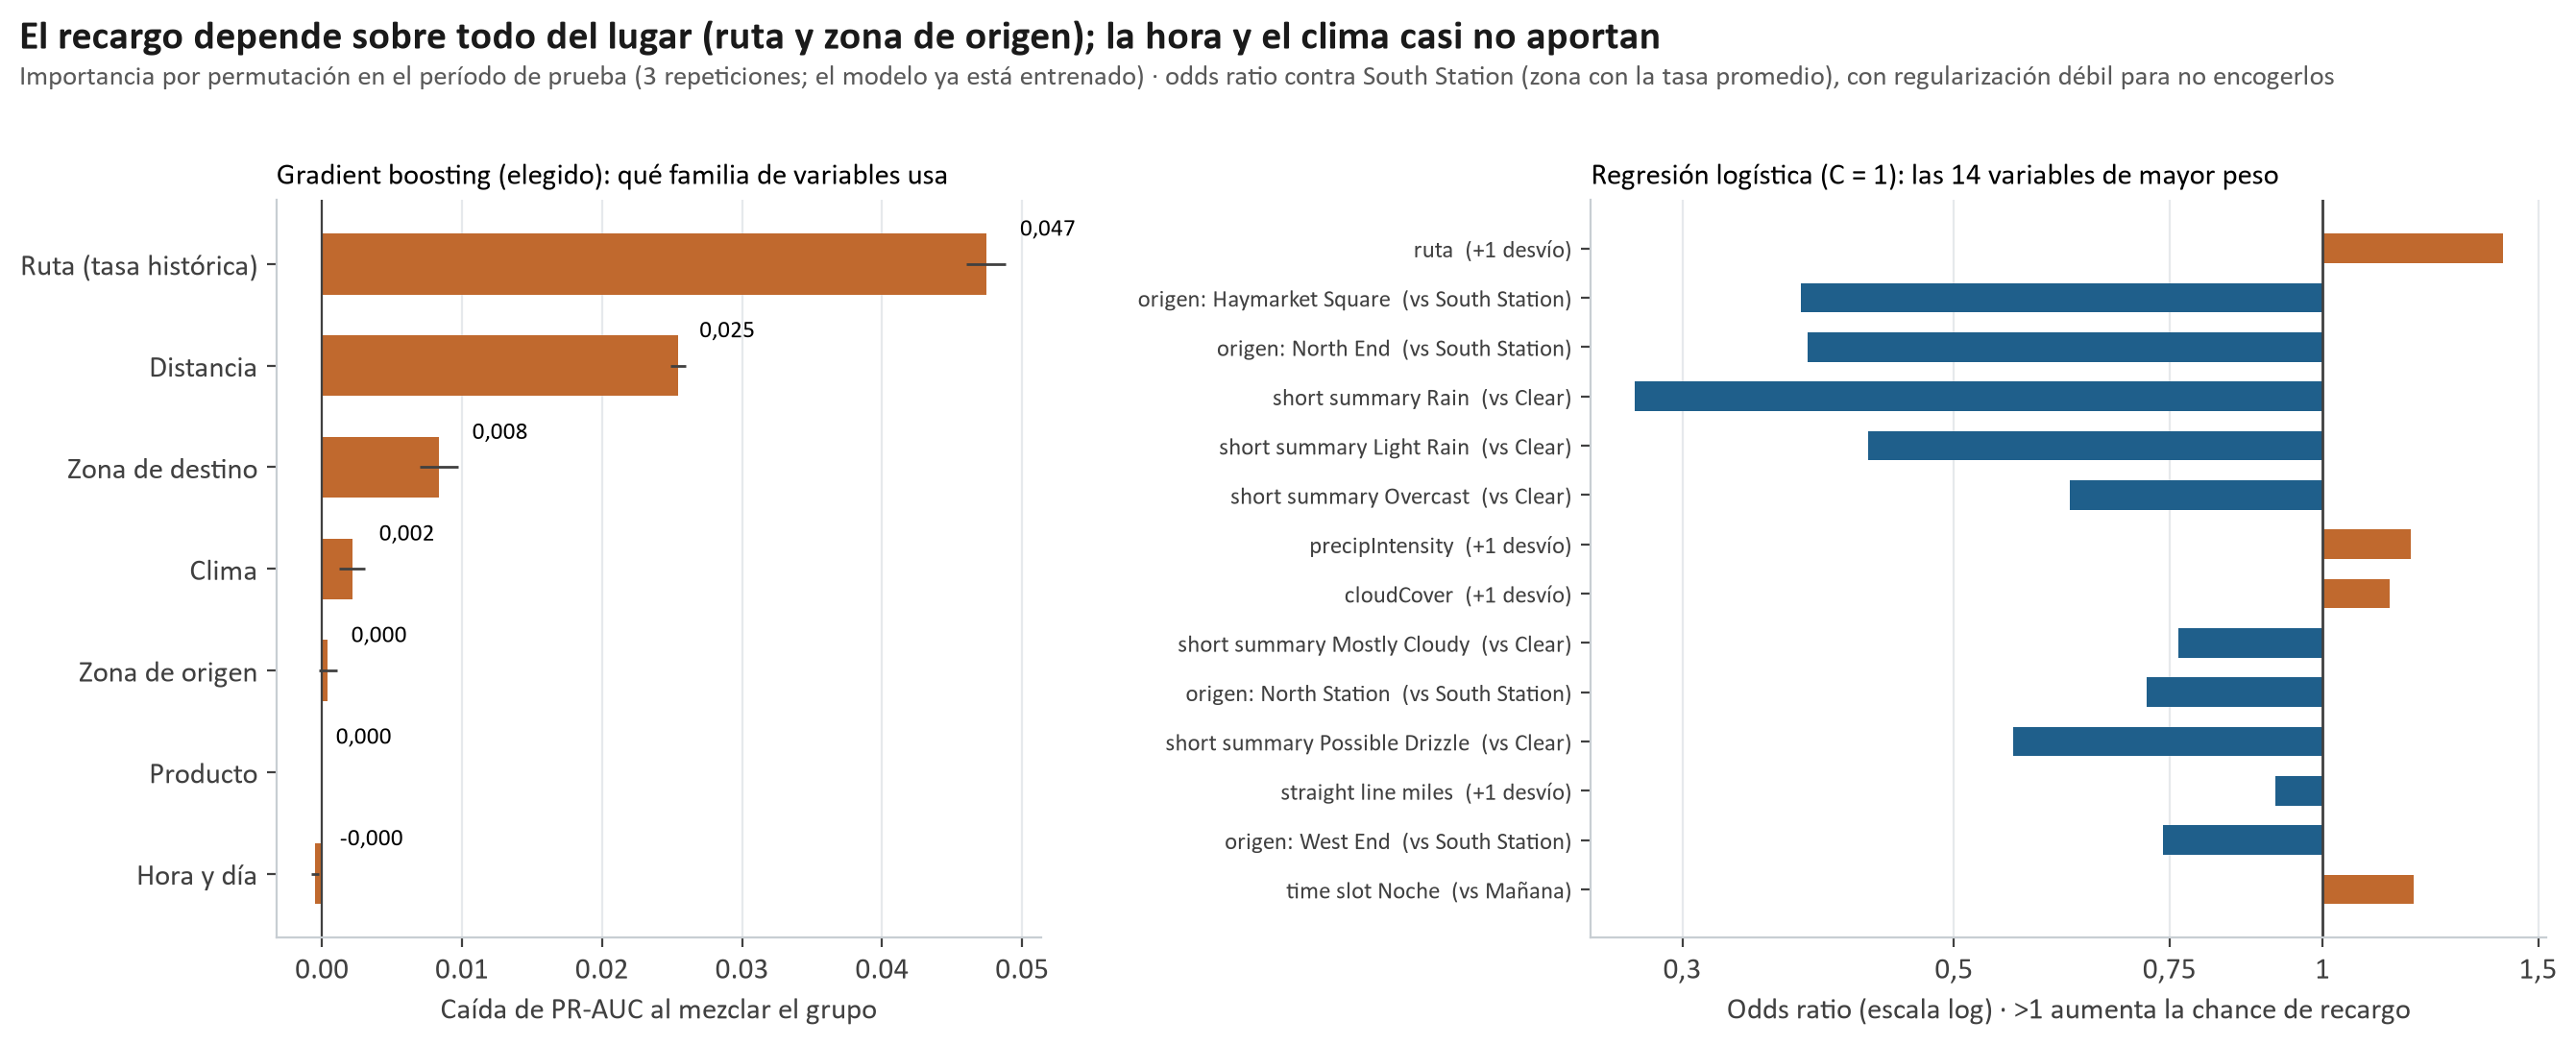

- **El lugar es lo que más importa:** la ruta y la zona de origen. La hora y el clima casi no aportan.
- Comparado con South Station (zona promedio), salir de **Northeastern University** multiplica la chance de recargo por 1,29 y de **Boston University**, por 1,24; salir de **Haymarket Square**, por 0,37.
- Los odds ratio salen de una logística con **regularización débil (C = 1)**: la logística elegida usa una C muy chica que los encoge hacia 1 (North End daría 0,65 en lugar de 0,38).

In [20]:
# @title Figura 8 · Qué variables pesan más { display-mode: "form" }
figura("fig08_recargo_importancia_odds_ratio.png")
o = {d["variable"]: d["odds_ratio"] for d in M["A_odds"]}
oe = {d["variable"]: d["odds_ratio"] for d in M["A_odds_elegida"]}
zonas = sorted(((k.replace("source_", "").replace("_", " "), v) for k, v in o.items() if k.startswith("source_")), key=lambda t: -t[1])
md(f"- **El lugar es lo que más importa:** la ruta y la zona de origen. La hora y el clima casi no aportan.\n"
   f"- Comparado con South Station (zona promedio), salir de **{zonas[0][0]}** multiplica la chance de recargo por {num(zonas[0][1], 2)} "
   f"y de **{zonas[1][0]}**, por {num(zonas[1][1], 2)}; salir de **{zonas[-1][0]}**, por {num(zonas[-1][1], 2)}.\n"
   f"- Los odds ratio salen de una logística con **regularización débil (C = {M['A_odds_info']['C_interpretar']:g})**: la logística elegida usa una C "
   f"muy chica que los encoge hacia 1 (North End daría {num(oe['source_North_End'], 2)} en lugar de {num(o['source_North_End'], 2)}).")

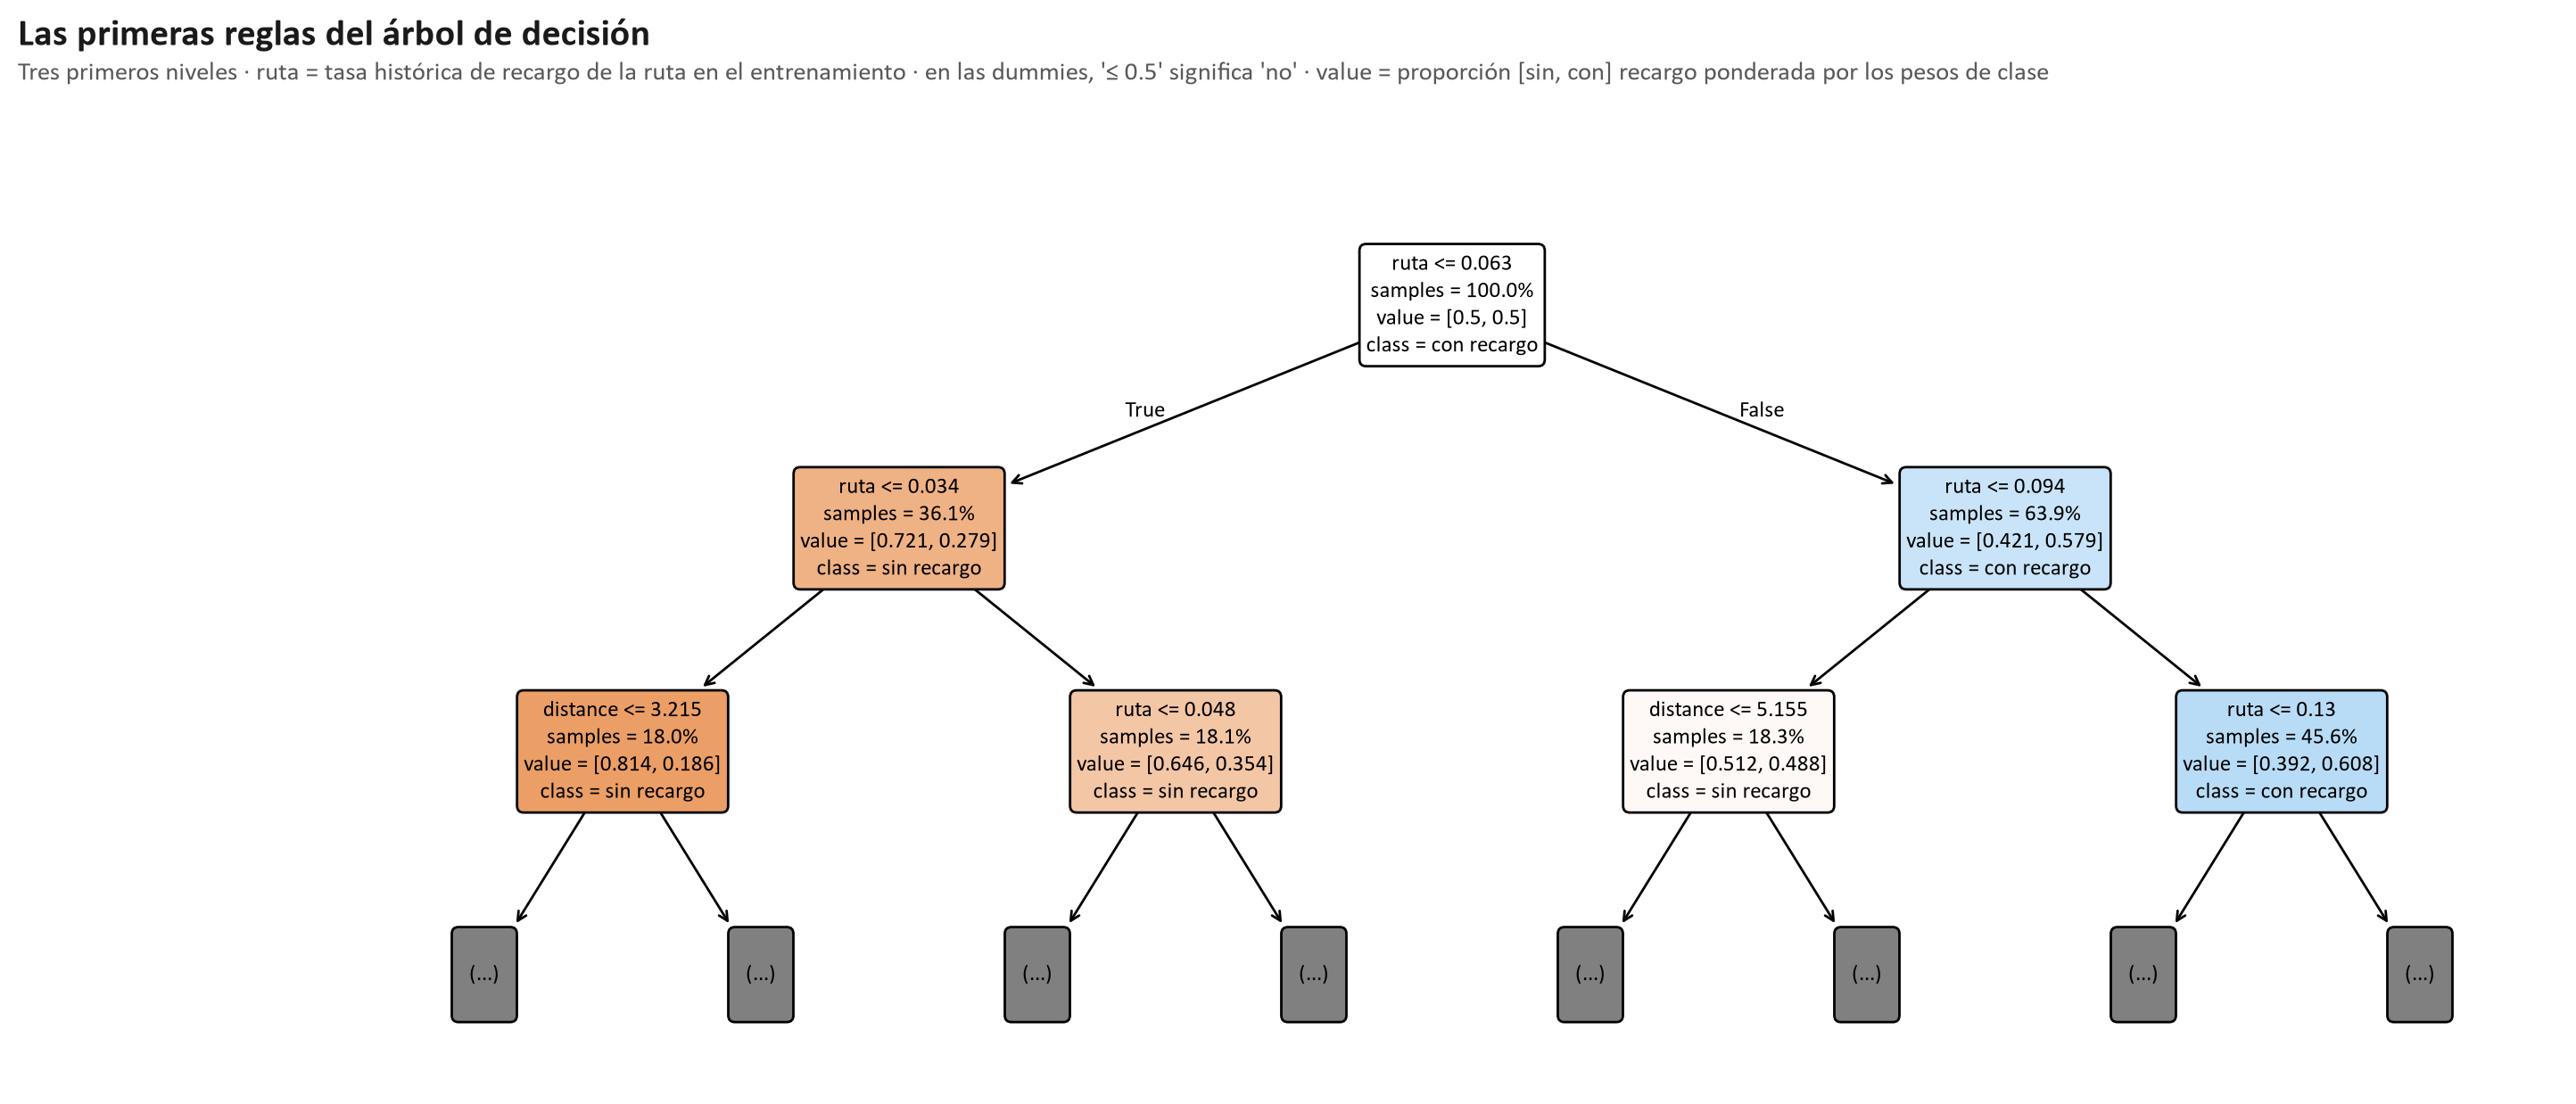

**Cómo leer el árbol:** cada caja hace una pregunta (por ejemplo, *¿la tasa histórica de recargo de la ruta es menor a X?*). Si la respuesta es sí se baja a la izquierda; si no, a la derecha. `value` es la proporción [sin, con] recargo en esa caja (ponderada por los pesos de clase): cuanto más naranja, más chance de recargo. El árbol separa primero por **lugar** y después por **distancia**.

In [21]:
# @title Figura 9 · El árbol de decisión: sus primeras reglas { display-mode: "form" }
figura("fig09_recargo_arbol_reglas.png")
md("**Cómo leer el árbol:** cada caja hace una pregunta (por ejemplo, *¿la tasa histórica de recargo de la ruta es menor a X?*). "
   "Si la respuesta es sí se baja a la izquierda; si no, a la derecha. `value` es la proporción [sin, con] recargo en esa caja "
   "(ponderada por los pesos de clase): cuanto más naranja, más chance de recargo. El árbol separa primero por **lugar** y después por **distancia**.")

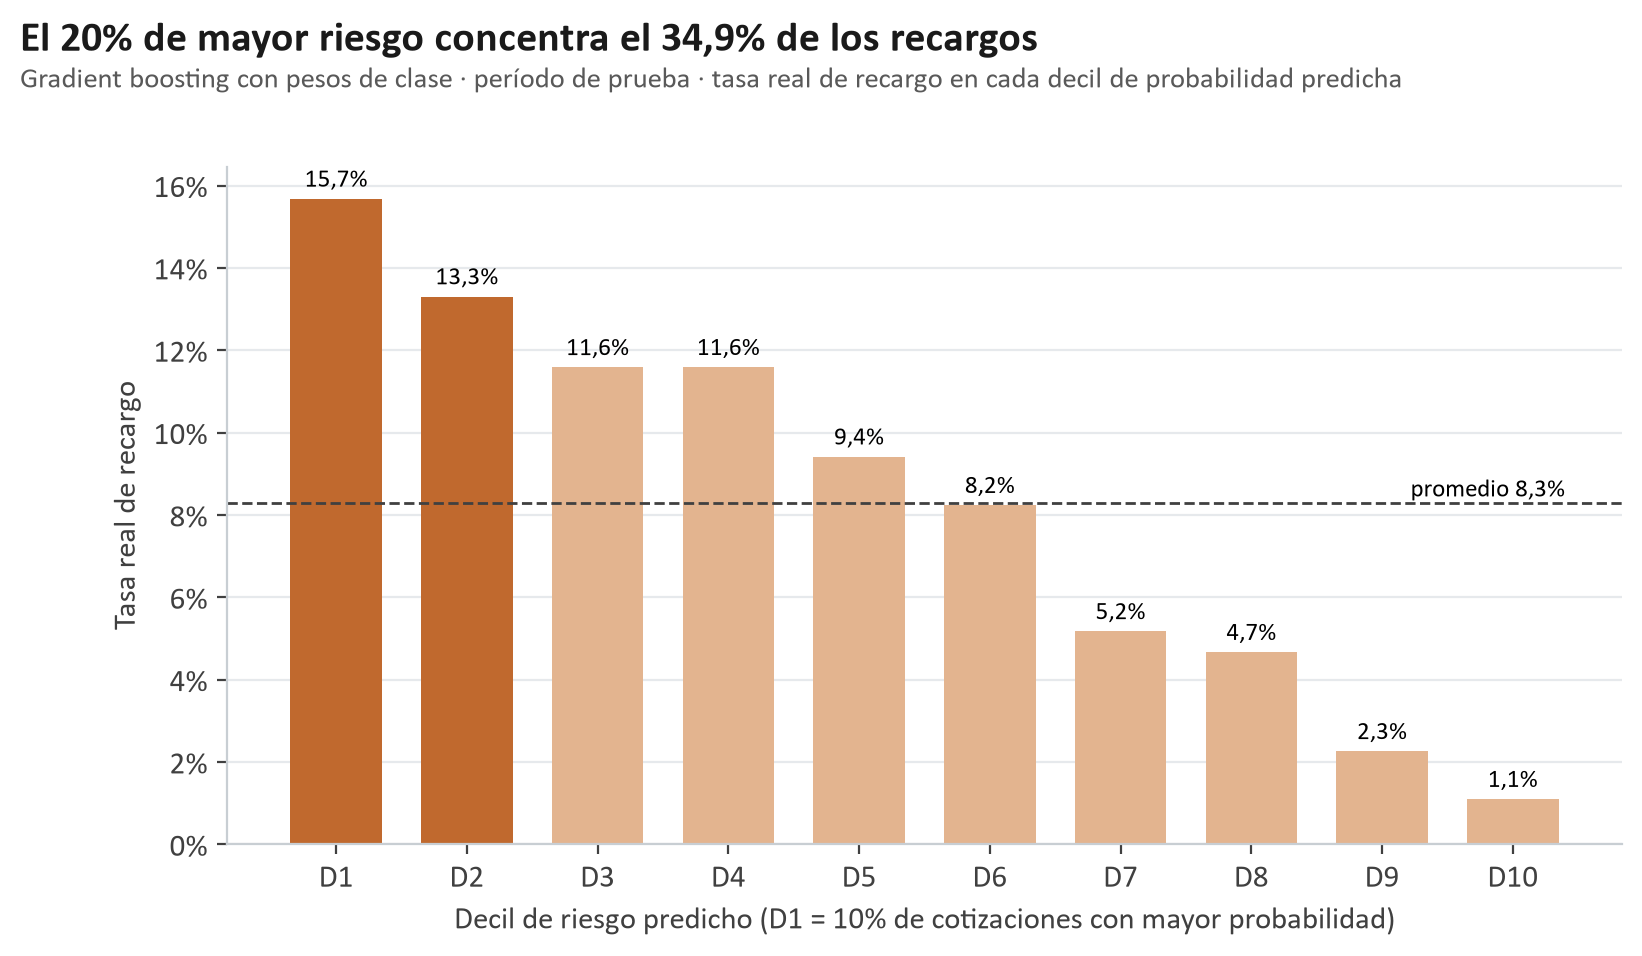

El modelo no adivina viaje por viaje, pero **ordena el riesgo**: el 10% de cotizaciones más riesgosas tiene 15,7% de recargos (1,9 veces el promedio) y el 10% menos riesgoso, 1,1%. El 20% más riesgoso concentra el **35%** de los recargos.

In [22]:
# @title Figura 10 · Uso práctico: ordenar el riesgo { display-mode: "form" }
figura("fig10_recargo_deciles_riesgo.png", 850)
d = M["A_deciles"]
md(f"El modelo no adivina viaje por viaje, pero **ordena el riesgo**: el 10% de cotizaciones más riesgosas tiene {pct(d[0]['tasa'])} de recargos "
   f"({num(d[0]['lift'], 1)} veces el promedio) y el 10% menos riesgoso, {pct(d[-1]['tasa'])}. "
   f"El 20% más riesgoso concentra el **{pct(d[1]['captura_acum'], 0)}** de los recargos.")

## 12 · Validación: por fecha vs mezclada

La **validación cruzada** repite el entrenamiento varias veces con distintas partes de los datos. En cada fold el balanceo se aplica solo a la parte de entrenamiento y se valida contra **datos reales**. Comparamos dos formas de armar los folds:

In [23]:
# @title Validación cruzada temporal vs mezclada · prueba por fecha vs al azar { display-mode: "form" }
filas = [[c["modelo"], f"{num(c['pr_auc_temporal'])} ± {num(c['pr_auc_temporal_std'])}",
          f"{num(c['pr_auc_mezclada'])} ± {num(c['pr_auc_mezclada_std'])}",
          f"+{100 * (c['pr_auc_mezclada'] / c['pr_auc_temporal'] - 1):.0f}%"] for c in M["A_cv_mezclada"]]
tabla(pd.DataFrame(filas, columns=["Modelo", "CV temporal en orden (4 folds)", "CV mezclada (5 folds estratificados)", "Diferencia"]))
filas = [[p["modelo"], num(p["pr_auc_temporal"]), num(p["pr_auc_aleatoria"]), f"+{100 * (p['pr_auc_aleatoria'] / p['pr_auc_temporal'] - 1):.0f}%"]
         for p in M["A_particion"]]
tabla(pd.DataFrame(filas, columns=["Modelo", "Prueba: 4 días nuevos", "Prueba: 25% al azar", "Diferencia"]))
md("**Mezclar las fechas hace parecer mejores a los modelos**, porque reconocen cotizaciones del mismo minuto y ruta que vieron al entrenar. "
   "Por eso elegimos con la validación cruzada **temporal**: es la estimación honesta de lo que pasaría con días nuevos.")

Modelo,CV temporal en orden (4 folds),CV mezclada (5 folds estratificados),Diferencia
Regresión logística,"0,120 ± 0,004","0,126 ± 0,003",+5%
Árbol de decisión,"0,125 ± 0,014","0,150 ± 0,005",+20%
Random forest,"0,126 ± 0,006","0,312 ± 0,005",+147%
Gradient boosting,"0,136 ± 0,012","0,178 ± 0,003",+31%


Modelo,Prueba: 4 días nuevos,Prueba: 25% al azar,Diferencia
Árbol de decisión,"0,138","0,153",+11%
Random forest,"0,142","0,309",+117%
Gradient boosting,"0,140","0,172",+23%


**Mezclar las fechas hace parecer mejores a los modelos**, porque reconocen cotizaciones del mismo minuto y ruta que vieron al entrenar. Por eso elegimos con la validación cruzada **temporal**: es la estimación honesta de lo que pasaría con días nuevos.

## 13 · Familias de tarifa (K-Means)

Para cada uno de los 12 productos calculamos **cuánto cobra por subir** (tarifa base) y **cuánto por milla**, con viajes sin recargo. Después los agrupamos con K-Means: el codo y la silueta marcan **k = 3** (silueta 0,68).

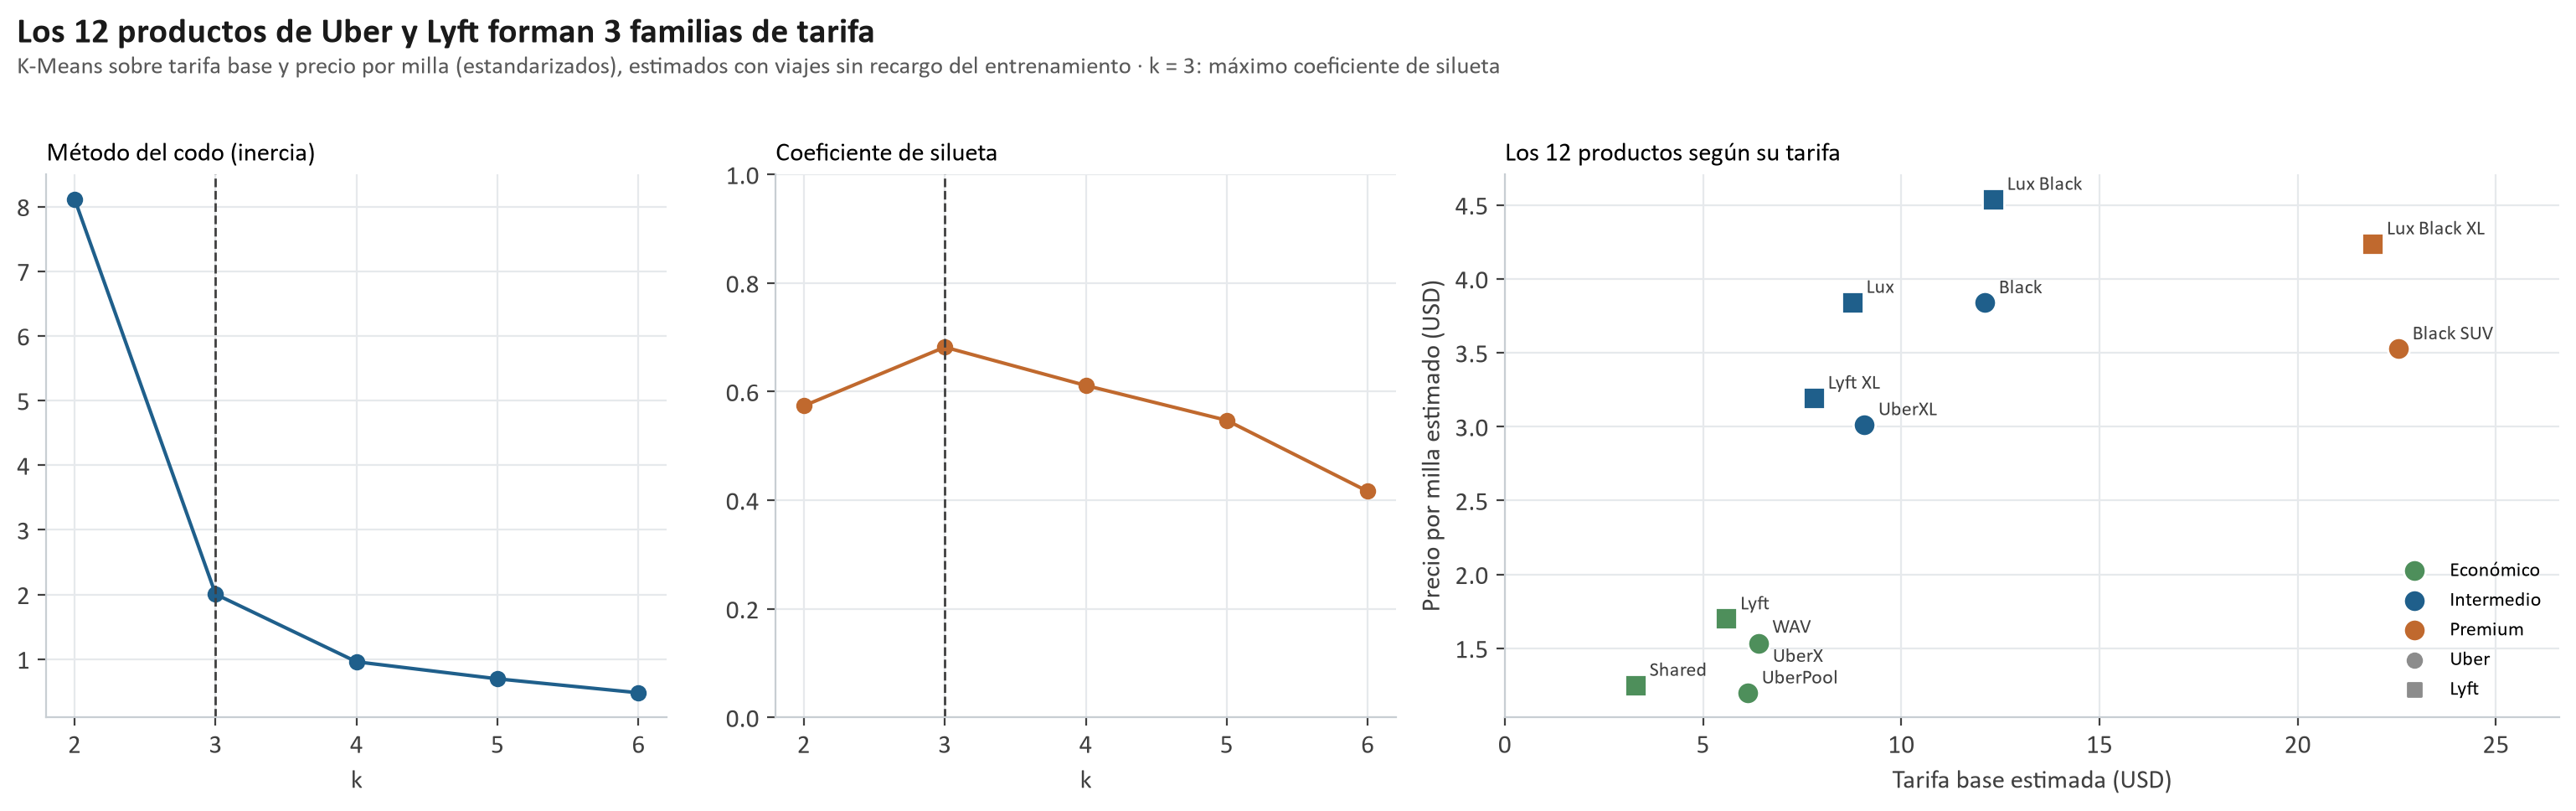

In [24]:
# @title Figura 11 · Los 12 productos según su tarifa { display-mode: "form" }
figura("fig11_productos_kmeans.png")

In [25]:
# @title Las tres familias { display-mode: "form" }
p = pd.read_csv(RES / "productos_perfil_clusters.csv")
tabla(pd.DataFrame({"Familia": p["grupo"], "Productos": p["lista"],
                    "Tarifa base": [f"USD {num(a, 1)} a {num(b, 1)}" for a, b in zip(p["tarifa_base_min"], p["tarifa_base_max"])],
                    "Por milla": [f"USD {num(a, 2)} a {num(b, 2)}" for a, b in zip(p["por_milla_min"], p["por_milla_max"])]}))
md("- **Uber y Lyft arman el precio igual:** cada producto de Uber cae en la misma familia que su equivalente de Lyft.\n"
   "- **Por qué los viajes cortos son caros por milla (H4):** la tarifa base se cobra siempre. Un UberX de 1 milla sale USD 7,94 por milla; uno de 5 millas, USD 2,81.")

Familia,Productos,Tarifa base,Por milla
Económico,"Shared, Lyft, UberPool, WAV, UberX","USD 3,3 a 6,4","USD 1,20 a 1,70"
Intermedio,"Lyft XL, Lux, UberXL, Black, Lux Black","USD 7,8 a 12,3","USD 3,01 a 4,54"
Premium,"Lux Black XL, Black SUV","USD 21,9 a 22,5","USD 3,53 a 4,24"


- **Uber y Lyft arman el precio igual:** cada producto de Uber cae en la misma familia que su equivalente de Lyft.
- **Por qué los viajes cortos son caros por milla (H4):** la tarifa base se cobra siempre. Un UberX de 1 milla sale USD 7,94 por milla; uno de 5 millas, USD 2,81.

## 14 · Conclusiones

In [26]:
# @title Hipótesis y respuesta al problema { display-mode: "form" }
md(f"""| Hipótesis | Resultado |
|---|---|
| H1 · Producto y distancia definen el precio | ✔ Confirmada (R² = {num(BM['r2'])}) |
| H2 · Uber y Lyft difieren según el nivel | ✔ Confirmada |
| H3 · Hay patrones horarios | ✘ No se confirma |
| H4 · Hay rutas más caras por milla | ✔ Confirmada (las cortas, por la tarifa base) |
| H5 · El mal clima encarece | ✘ Rechazada |
| H6 · Hay segmentos tarifarios | ✔ Confirmada (3 familias de productos) |

### Respuesta al problema

1. **El precio es predecible:** con el producto, la distancia y el multiplicador se estima con un error de {usd(BM['mae'])} ({usd(BS['mae'])} sin el multiplicador).
2. **El recargo es lo difícil de anticipar:** depende del **lugar**, no de la hora ni del clima. Lo demás depende de la oferta y la demanda en tiempo real, que no están en los datos (ROC-AUC {num(FIN['roc_auc'])}).
3. **La accuracy sola engaña:** {pct(FIN['accuracy'])} del modelo contra 91,7% de decir siempre que no. La mejora real se ve en la accuracy balanceada ({pct(FIN['accuracy_balanceada'])}) y en el beneficio.
4. **La matriz de beneficio define cómo usarlo:** avisos selectivos, de bajo costo para el pasajero (USD {FIN['beneficio_1000']:.0f} de beneficio cada 1.000 cotizaciones con el supuesto de USD 1 por falsa alarma).
5. **Valor práctico:** si salís de Back Bay, Fenway o las universidades, conviene **comparar con Uber** o caminar a una zona vecina.

**Próximo paso (Entrega 4):** contar esta historia para el pasajero, el conductor y la plataforma.""")

| Hipótesis | Resultado |
|---|---|
| H1 · Producto y distancia definen el precio | ✔ Confirmada (R² = 0,967) |
| H2 · Uber y Lyft difieren según el nivel | ✔ Confirmada |
| H3 · Hay patrones horarios | ✘ No se confirma |
| H4 · Hay rutas más caras por milla | ✔ Confirmada (las cortas, por la tarifa base) |
| H5 · El mal clima encarece | ✘ Rechazada |
| H6 · Hay segmentos tarifarios | ✔ Confirmada (3 familias de productos) |

### Respuesta al problema

1. **El precio es predecible:** con el producto, la distancia y el multiplicador se estima con un error de USD 1,08 (USD 1,32 sin el multiplicador).
2. **El recargo es lo difícil de anticipar:** depende del **lugar**, no de la hora ni del clima. Lo demás depende de la oferta y la demanda en tiempo real, que no están en los datos (ROC-AUC 0,676).
3. **La accuracy sola engaña:** 68,6% del modelo contra 91,7% de decir siempre que no. La mejora real se ve en la accuracy balanceada (60,8%) y en el beneficio.
4. **La matriz de beneficio define cómo usarlo:** avisos selectivos, de bajo costo para el pasajero (USD 56 de beneficio cada 1.000 cotizaciones con el supuesto de USD 1 por falsa alarma).
5. **Valor práctico:** si salís de Back Bay, Fenway o las universidades, conviene **comparar con Uber** o caminar a una zona vecina.

**Próximo paso (Entrega 4):** contar esta historia para el pasajero, el conductor y la plataforma.

---
### Anexo · Dónde está cada cosa

| Carpeta | Contenido |
|---|---|
| `1_Informe/` | Informe completo, con todos los detalles técnicos |
| `3_Codigo/` | `modelado_entrega3.py`: reproduce todo |
| `4_Datasets/` | Datasets de modelado y balanceados |
| `5_Graficos/` y `6_Resultados/` | Figuras y tablas |
| `Modelos/README.md` | Cómo hicimos cada modelo, paso a paso |